# **New York City Yellow Taxi Data**

## Objective
In this case study you will be learning exploratory data analysis (EDA) with the help of a dataset on yellow taxi rides in New York City. This will enable you to understand why EDA is an important step in the process of data science and machine learning.

## **Problem Statement**
As an analyst at an upcoming taxi operation in NYC, you are tasked to use the 2023 taxi trip data to uncover insights that could help optimise taxi operations. The goal is to analyse patterns in the data that can inform strategic decisions to improve service efficiency, maximise revenue, and enhance passenger experience.

## Tasks
You need to perform the following steps for successfully completing this assignment:
1. Data Loading
2. Data Cleaning
3. Exploratory Analysis: Bivariate and Multivariate
4. Creating Visualisations to Support the Analysis
5. Deriving Insights and Stating Conclusions

---

**NOTE:** The marks given along with headings and sub-headings are cumulative marks for those particular headings/sub-headings.<br>

The actual marks for each task are specified within the tasks themselves.

For example, marks given with heading *2* or sub-heading *2.1* are the cumulative marks, for your reference only. <br>

The marks you will receive for completing tasks are given with the tasks.

Suppose the marks for two tasks are: 3 marks for 2.1.1 and 2 marks for 3.2.2, or
* 2.1.1 [3 marks]
* 3.2.2 [2 marks]

then, you will earn 3 marks for completing task 2.1.1 and 2 marks for completing task 3.2.2.


---

## Data Understanding
The yellow taxi trip records include fields capturing pick-up and drop-off dates/times, pick-up and drop-off locations, trip distances, itemized fares, rate types, payment types, and driver-reported passenger counts.

The data is stored in Parquet format (*.parquet*). The dataset is from 2009 to 2024. However, for this assignment, we will only be using the data from 2023.

The data for each month is present in a different parquet file. You will get twelve files for each of the months in 2023.

The data was collected and provided to the NYC Taxi and Limousine Commission (TLC) by technology providers like vendors and taxi hailing apps. <br>

You can find the link to the TLC trip records page here: https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page

THE ABOVE LINK IS JUST FOR REFERENCE - PLEASE DO NOT USE THE DATASET PROVIDED IN THE ABOVE WEBPAGE FOR SOLVING THE ASSIGNMENT.

**Trip Records**



|Field Name       |description |
|:----------------|:-----------|
| VendorID | A code indicating the TPEP provider that provided the record. <br> 1= Creative Mobile Technologies, LLC; <br> 2= VeriFone Inc. |
| tpep_pickup_datetime | The date and time when the meter was engaged.  |
| tpep_dropoff_datetime | The date and time when the meter was disengaged.   |
| Passenger_count | The number of passengers in the vehicle. <br> This is a driver-entered value. |
| Trip_distance | The elapsed trip distance in miles reported by the taximeter. |
| PULocationID | TLC Taxi Zone in which the taximeter was engaged |
| DOLocationID | TLC Taxi Zone in which the taximeter was disengaged |
|RateCodeID |The final rate code in effect at the end of the trip.<br> 1 = Standard rate <br> 2 = JFK <br> 3 = Newark <br>4 = Nassau or Westchester <br>5 = Negotiated fare <br>6 = Group ride |
|Store_and_fwd_flag |This flag indicates whether the trip record was held in vehicle memory before sending to the vendor, aka “store and forward,” because the vehicle did not have a connection to the server.  <br>Y= store and forward trip <br>N= not a store and forward trip |
|Payment_type| A numeric code signifying how the passenger paid for the trip. <br> 1 = Credit card <br>2 = Cash <br>3 = No charge <br>4 = Dispute <br>5 = Unknown <br>6 = Voided trip |
|Fare_amount| The time-and-distance fare calculated by the meter. <br>Extra Miscellaneous extras and surcharges.  Currently, this only includes the 0.50 and 1 USD rush hour and overnight charges. |
|MTA_tax |0.50 USD MTA tax that is automatically triggered based on the metered rate in use. |
|Improvement_surcharge | 0.30 USD improvement surcharge assessed trips at the flag drop. The improvement surcharge began being levied in 2015. |
|Tip_amount |Tip amount – This field is automatically populated for credit card tips. Cash tips are not included. |
| Tolls_amount | Total amount of all tolls paid in trip.  |
| total_amount | The total amount charged to passengers. Does not include cash tips. |
|Congestion_Surcharge |Total amount collected in trip for NYS congestion surcharge. |
| Airport_fee | 1.25 USD for pick up only at LaGuardia and John F. Kennedy Airports|

Although the amounts of extra charges and taxes applied are specified in the data dictionary, you will see that some cases have different values of these charges in the actual data.

**Taxi Zones**

Each of the trip records contains a field corresponding to the location of the pickup or drop-off of the trip, populated by numbers ranging from 1-263.

These numbers correspond to taxi zones, which may be downloaded as a table or map/shapefile and matched to the trip records using a join.

This is covered in more detail in later sections.

---

## **1** Data Preparation

<font color = red>[5 marks]</font> <br>

### Import Libraries

In [1]:
# Import warnings
import warnings


In [2]:
# Import the libraries you will be using for analysis
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Recommended versions
# numpy version: 1.26.4
# pandas version: 2.2.2
# matplotlib version: 3.10.0
# seaborn version: 0.13.2

# Check versions
print("numpy version:", np.__version__)
print("pandas version:", pd.__version__)
print("matplotlib version:", plt.matplotlib.__version__)
print("seaborn version:", sns.__version__)

numpy version: 2.1.3
pandas version: 2.2.3
matplotlib version: 3.10.0
seaborn version: 0.13.2


### **1.1** Load the dataset
<font color = red>[5 marks]</font> <br>

You will see twelve files, one for each month.

To read parquet files with Pandas, you have to follow a similar syntax as that for CSV files.

`df = pd.read_parquet('file.parquet')`

In [18]:
# Try loading one file

df = pd.read_parquet('/content/2023-1.parquet')
df.info()

NameError: name 'pd' is not defined

How many rows are there? Do you think handling such a large number of rows is computationally feasible when we have to combine the data for all twelve months into one?

To handle this, we need to sample a fraction of data from each of the files. How to go about that? Think of a way to select only some portion of the data from each month's file that accurately represents the trends.

#### Sampling the Data
> One way is to take a small percentage of entries for pickup in every hour of a date. So, for all the days in a month, we can iterate through the hours and select 5% values randomly from those. Use `tpep_pickup_datetime` for this. Separate date and hour from the datetime values and then for each date, select some fraction of trips for each of the 24 hours.

To sample data, you can use the `sample()` method. Follow this syntax:

```Python
# sampled_data is an empty DF to keep appending sampled data of each hour
# hour_data is the DF of entries for an hour 'X' on a date 'Y'

sample = hour_data.sample(frac = 0.05, random_state = 42)
# sample 0.05 of the hour_data
# random_state is just a seed for sampling, you can define it yourself

sampled_data = pd.concat([sampled_data, sample]) # adding data for this hour to the DF
```

This *sampled_data* will contain 5% values selected at random from each hour.

Note that the code given above is only the part that will be used for sampling and not the complete code required for sampling and combining the data files.

Keep in mind that you sample by date AND hour, not just hour. (Why?)

---

**1.1.1** <font color = red>[5 marks]</font> <br>
Figure out how to sample and combine the files.

**Note:** It is not mandatory to use the method specified above. While sampling, you only need to make sure that your sampled data represents the overall data of all the months accurately.

In [19]:
# Sample the data
# It is recommmended to not load all the files at once to avoid memory overload
import io
import zipfile
import pandas as pd
from google.colab import drive

In [20]:
# from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [21]:
# Take a small percentage of entries from each hour of every date.
# Iterating through the monthly data:
#  read a month file -> day -> hour: append sampled data -> move to next hour -> move to next day after 24 hours -> move to next month file
# Create a single dataframe for the year combining all the monthly data

# Select the folder having data files
import os

# Select the folder having data files
#os.chdir('/content/Assignments/EDA/data_NYC_Taxi/trip_records')
ZIP_FILE_PATH = "/content/drive/MyDrive/Datasets and Dictionary-NYC.zip"
SAMPLE_FRACTION = 0.05  # Adjust this fraction as needed (e.g., 0.05 = 5%)
sampled_dataframes = []

# Create a list of all the twelve files to read
#file_list = os.listdir()
sampled_chunks = []

# initialise an empty dataframe
df = pd.DataFrame()

with zipfile.ZipFile(ZIP_FILE_PATH, 'r') as archive:

  all_zip_contents = archive.namelist()
  file_list = [f for f in all_zip_contents if f.startswith("Datasets and Dictionary/trip_records/") and f.endswith(".parquet")]

  print(f"Found {len(file_list)} parquet files to process.")


  # iterate through the list of files and sample one by one:
  for file_name in file_list:
    try:
        # file path for the current file
        print(f"Processing and sampling: {os.path.basename(file_name)}")

        # Reading the current file
        with archive.open(file_name) as file_data:
                file_bytes = io.BytesIO(file_data.read())
        df_month = pd.read_parquet(file_bytes)

        # Sample the current file
        df_sample = df_month.sample(frac=SAMPLE_FRACTION, random_state=42)
        df_sample.reset_index(drop=True, inplace=True)


        # We will store the sampled data for the current date in this df by appending the sampled data from each hour to this
        # After completing iteration through each date, we will append this data to the final dataframe.
        df = pd.concat([df, df_sample], ignore_index=True)

        # Loop through dates and then loop through every hour of each date
        pickup_col = 'tpep_pickup_datetime'
        df_month[pickup_col] = pd.to_datetime(df_month[pickup_col])
        df_month['pickup_date'] = df_month[pickup_col].dt.date
        df_month['pickup_hour'] = df_month[pickup_col].dt.hour
        unique_dates = sorted(df_month['pickup_date'].unique())
        for current_date in unique_dates:
                # Filter data for the specific day
                df_day = df_month[df_month['pickup_date'] == current_date]
                # Loop through every hour of each date
                for current_hour in range(24):
                    # Iterate through each hour of the selected date
                    df_hour = df_day[df_day['pickup_hour'] == current_hour]

                    # Skip if there are no trips in this specific hour
                    if df_hour.empty:
                        continue

                    # Sample 5% of the hourly data randomly
                    df_sample = df_hour.sample(frac=SAMPLE_FRACTION, random_state=42)
                    df_sample.reset_index(drop=True, inplace=True)

                    # add data of this hour to the dataframe list
                    sampled_chunks.append(df_sample)

    except Exception as e:
        print(f"Error reading file {file_name}: {e}")


# Concatenate the sampled data of all the dates to a single dataframe
if sampled_chunks:
    df = pd.concat(sampled_chunks, ignore_index=True)

    # Cleanup helper columns before exporting
    df.drop(columns=['pickup_date', 'pickup_hour'], inplace=True, errors='ignore')

    # 4. Export the combined dataframe back to Google Drive
    output_filename = "/content/drive/MyDrive/combined_yellow_tripdata_2023_sample.parquet"
    df.to_parquet(output_filename, index=False)
    print(f"\nData preparation complete! Saved to Drive as: {output_filename}")
    print(f"Total rows in sample dataset: {len(df)}")
else:
    print("\nError: Master dataframe is empty. No data was loaded.")

Found 12 parquet files to process.
Processing and sampling: 2023-9.parquet
Processing and sampling: 2023-5.parquet
Processing and sampling: 2023-6.parquet
Processing and sampling: 2023-2.parquet
Processing and sampling: 2023-1.parquet
Processing and sampling: 2023-8.parquet
Processing and sampling: 2023-7.parquet
Processing and sampling: 2023-10.parquet
Processing and sampling: 2023-3.parquet
Processing and sampling: 2023-12.parquet
Processing and sampling: 2023-4.parquet
Processing and sampling: 2023-11.parquet

Data preparation complete! Saved to Drive as: /content/drive/MyDrive/combined_yellow_tripdata_2023_sample.parquet
Total rows in sample dataset: 1896400


After combining the data files into one DataFrame, convert the new DataFrame to a CSV or parquet file and store it to use directly.

Ideally, you can try keeping the total entries to around 250,000 to 300,000.

In [22]:
# Store the df in csv/parquet
# df.to_parquet('')

## **2** Data Cleaning
<font color = red>[30 marks]</font> <br>

Now we can load the new data directly.

In [23]:
# Load the new data file
INPUT_FILENAME = "/content/drive/MyDrive/combined_yellow_tripdata_2023_sample.parquet"

try:
    # 3. Load the new data file into a Pandas DataFrame
    df_loaded = pd.read_parquet(INPUT_FILENAME)

    # 4. Print summary statistics to verify the row counts and columns
    print("Data loaded successfully!")
    print(f"Total Rows: {df_loaded.shape[0]}")
    print(f"Total Columns: {df_loaded.shape[1]}")
except FileNotFoundError:
    print(f"Error: Could not find the file at {INPUT_FILENAME}. Please check the path.")
except Exception as e:
    print(f"An error occurred while loading the file: {e}")

Data loaded successfully!
Total Rows: 1896400
Total Columns: 20


In [24]:
# df.head()
try:
  print("\n--- First 5 rows ---")
  display(df_loaded.head())
except Exception as e:
    print(f"An error occurred while loading the file: {e}")


--- First 5 rows ---


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,airport_fee
0,2,2023-08-31 23:56:01,2023-09-01 00:18:41,1.0,3.11,1.0,N,114,246,1,21.20,1.0,0.5,0.00,0.00,1.0,26.20,2.5,0.00,NaN
1,2,2023-09-01 00:39:59,2023-09-01 01:00:28,NaN,4.71,NaN,None,113,238,0,24.83,0.0,0.5,4.32,0.00,1.0,33.15,NaN,NaN,NaN
2,2,2023-09-01 00:24:50,2023-09-01 00:27:19,2.0,0.56,1.0,N,142,142,2,5.10,1.0,0.5,0.00,0.00,1.0,10.10,2.5,0.00,NaN
3,2,2023-09-01 00:19:27,2023-09-01 01:04:02,2.0,18.46,2.0,N,132,163,1,70.00,0.0,0.5,15.71,6.94,1.0,98.40,2.5,1.75,NaN
4,2,2023-09-01 00:42:13,2023-09-01 01:20:20,2.0,13.71,1.0,N,249,180,4,59.70,1.0,0.5,0.00,0.00,1.0,64.70,2.5,0.00,NaN


In [25]:
df_loaded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1896400 entries, 0 to 1896399
Data columns (total 20 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int64         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     object        
 7   PULocationID           int64         
 8   DOLocationID           int64         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airport_fee           

#### **2.1** Fixing Columns
<font color = red>[10 marks]</font> <br>

Fix/drop any columns as you seem necessary in the below sections

**2.1.1** <font color = red>[2 marks]</font> <br>

Fix the index and drop unnecessary columns

In [26]:
# Fix the index and drop any columns that are not needed
# drop vendor id
df_loaded.reset_index(drop=True, inplace=True)
columns_to_drop = ['VendorID']
df_loaded.drop(columns=columns_to_drop, inplace=True, errors='ignore')
print("Index fixed and specified columns dropped!")
print(f"New DataFrame shape: {df_loaded.shape}")
print("\n--- Updated Columns Remaining ---")
print(df_loaded.columns.tolist())

Index fixed and specified columns dropped!
New DataFrame shape: (1896400, 19)

--- Updated Columns Remaining ---
['tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'airport_fee']


**2.1.2** <font color = red>[3 marks]</font> <br>
There are two airport fee columns. This is possibly an error in naming columns. Let's see whether these can be combined into a single column.

In [27]:
nan_count = df_loaded['airport_fee'].isna().sum()
print(f"Number of NaN values in airport_fee: {nan_count}")
nan_percentage = df_loaded['airport_fee'].isna().mean() * 100
print(f"Percentage of missing airport_fee data: {nan_percentage:.2f}%")

Number of NaN values in airport_fee: 1747917
Percentage of missing airport_fee data: 92.17%


In [28]:
# Combine the two airport fee columns

# 1. Combine the columns: Airport_fee takes priority; fills NaNs using airport_fee
df_loaded['Airport_fee'] = df_loaded['Airport_fee'].combine_first(df_loaded['airport_fee'])

# 2. Drop the redundant lowercase column
df_loaded.drop(columns=['airport_fee'], inplace=True, errors='ignore')

# 3. Verify the remaining NaN count in the combined column
remaining_nans = df_loaded['Airport_fee'].isna().sum()
print(f"Remaining NaNs in 'Airport_fee': {remaining_nans}")


Remaining NaNs in 'Airport_fee': 64874


**2.1.3** <font color = red>[5 marks]</font> <br>
Fix columns with negative (monetary) values

In [29]:
# check where values of fare amount are negative
negative_fares = df_loaded[df_loaded['fare_amount'] < 0]

print(f"Total rows with negative fares: {len(negative_fares)}")
display(negative_fares.head())

Total rows with negative fares: 0


,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee


Did you notice something different in the `RatecodeID` column for above records?

In [30]:
# Analyse RatecodeID for the negative fare amounts
ratecode_counts = negative_fares['RatecodeID'].value_counts()
print("--- Number of Negative Fares by RatecodeID ---")
print(ratecode_counts)

--- Number of Negative Fares by RatecodeID ---
Series([], Name: count, dtype: int64)


In [31]:
# Find which columns have negative values
numeric_df = df_loaded.select_dtypes(include=['number'])

# Find columns where at least one value is negative, and count them
negative_counts = (numeric_df < 0).sum()
columns_with_negatives = negative_counts[negative_counts > 0]

print("--- Columns with Negative Values ---")
if not columns_with_negatives.empty:
    print(columns_with_negatives)
else:
    print("No columns contain negative values!")


--- Columns with Negative Values ---
extra                     3
mta_tax                  73
improvement_surcharge    78
total_amount             78
congestion_surcharge     56
Airport_fee              15
dtype: int64


In [32]:
# fix these negative values
columns_to_zero = ['mta_tax', 'extra', 'improvement_surcharge', 'congestion_surcharge', 'Airport_fee', 'total_amount']

# Replace negative values with 0 in the specified columns
for col in columns_to_zero:
    if col in df_loaded.columns:
        # Using .clip(lower=0) automatically turns any value below 0 into 0
        df_loaded[col] = df_loaded[col].clip(lower=0)

print("Fixed! Negative values in taxes and surcharges have been replaced with 0.")

# Verify that no negatives remain in these specific columns
print("\n--- Remaining negative values ---")
print((df_loaded[columns_to_zero] < 0).sum())


Fixed! Negative values in taxes and surcharges have been replaced with 0.

--- Remaining negative values ---
mta_tax                  0
extra                    0
improvement_surcharge    0
congestion_surcharge     0
Airport_fee              0
total_amount             0
dtype: int64


### **2.2** Handling Missing Values
<font color = red>[10 marks]</font> <br>

**2.2.1**  <font color = red>[2 marks]</font> <br>
Find the proportion of missing values in each column




In [33]:
# Find the proportion of missing values in each column
missing_proportion = df_loaded.isna().mean()

print("--- Proportion of Missing Values per Column ---")
print(missing_proportion)


--- Proportion of Missing Values per Column ---
tpep_pickup_datetime     0.000000
tpep_dropoff_datetime    0.000000
passenger_count          0.034209
trip_distance            0.000000
RatecodeID               0.034209
store_and_fwd_flag       0.034209
PULocationID             0.000000
DOLocationID             0.000000
payment_type             0.000000
fare_amount              0.000000
extra                    0.000000
mta_tax                  0.000000
tip_amount               0.000000
tolls_amount             0.000000
improvement_surcharge    0.000000
total_amount             0.000000
congestion_surcharge     0.034209
Airport_fee              0.034209
dtype: float64


**2.2.2**  <font color = red>[3 marks]</font> <br>
Handling missing values in `passenger_count`

In [34]:
# Display the rows with null values
# This filters the DataFrame to show rows where any column contains a NaN value
df_with_nulls = df_loaded[df_loaded.isna().any(axis=1)]
print(f"Total rows containing at least one missing value: {len(df_with_nulls)}")
print("\n--- Sample of Rows with Null Values ---")
display(df_with_nulls.head())

# Impute NaN values in 'passenger_count'
if 'passenger_count' in df_loaded.columns:
    # Calculate the mode (most common value) for passenger_count
    passenger_mode = df_loaded['passenger_count'].mode()[0]

    # Fill the NaN values with the calculated mode
    df_loaded['passenger_count'].fillna(passenger_mode, inplace=True)

    print(f"\nImputation Complete! Missing 'passenger_count' values filled with the mode: {passenger_mode}")
    # Verify remaining NaNs in passenger_count
    print(f"Remaining NaNs in passenger_count: {df_loaded['passenger_count'].isna().sum()}")

Total rows containing at least one missing value: 64874

--- Sample of Rows with Null Values ---


,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
1,2023-09-01 00:39:59,2023-09-01 01:00:28,NaN,4.71,NaN,None,113,238,0,24.83,0.0,0.5,4.32,0.0,1.0,33.15,NaN,NaN
86,2023-09-01 00:01:15,2023-09-01 00:07:07,NaN,1.07,NaN,None,148,4,0,11.88,0.0,0.5,2.00,0.0,1.0,17.88,NaN,NaN
152,2023-09-01 01:58:13,2023-09-01 02:12:29,NaN,3.32,NaN,None,211,230,0,19.04,0.0,0.5,4.61,0.0,1.0,27.65,NaN,NaN
204,2023-09-01 01:08:34,2023-09-01 01:20:38,NaN,2.67,NaN,None,144,65,0,19.89,0.0,0.5,4.30,0.0,1.0,28.19,NaN,NaN
252,2023-09-01 02:29:04,2023-09-01 02:45:34,NaN,0.00,NaN,None,79,48,0,19.85,0.0,0.5,0.00,0.0,1.0,23.85,NaN,NaN



Imputation Complete! Missing 'passenger_count' values filled with the mode: 1.0
Remaining NaNs in passenger_count: 0


/tmp/ipykernel_1228/3313264624.py:14: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_loaded['passenger_count'].fillna(passenger_mode, inplace=True)


Did you find zeroes in passenger_count? Handle these.

**2.2.3**  <font color = red>[2 marks]</font> <br>
Handle missing values in `RatecodeID`

In [35]:
# Fix missing values in 'RatecodeID'

# The final rate code in effect at the end of the trip. 1= Standard rate

if 'RatecodeID' in df_loaded.columns:
    df_loaded['RatecodeID'].fillna(1, inplace=True)

    print("Fixed! Missing values in 'RatecodeID' have been filled with 1.")
    # Verify remaining NaNs in the column
    print(f"Remaining NaNs in RatecodeID: {df_loaded['RatecodeID'].isna().sum()}")


Fixed! Missing values in 'RatecodeID' have been filled with 1.
Remaining NaNs in RatecodeID: 0


/tmp/ipykernel_1228/716021968.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_loaded['RatecodeID'].fillna(1, inplace=True)


**2.2.4**  <font color = red>[3 marks]</font> <br>
Impute NaN in `congestion_surcharge`

In [36]:
# handle null values in congestion_surcharge

if 'congestion_surcharge' in df_loaded.columns:
    df_loaded['congestion_surcharge'].fillna(0, inplace=True)

    print("Fixed! Missing values in 'congestion_surcharge' have been filled with 0.")
    # Verify remaining NaNs in the column
    print(f"Remaining NaNs in congestion_surcharge: {df_loaded['congestion_surcharge'].isna().sum()}")


Fixed! Missing values in 'congestion_surcharge' have been filled with 0.
Remaining NaNs in congestion_surcharge: 0


/tmp/ipykernel_1228/3699621179.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_loaded['congestion_surcharge'].fillna(0, inplace=True)


Are there missing values in other columns? Did you find NaN values in some other set of columns? Handle those missing values below.

In [37]:
# Handle any remaining missing values

# Handle null values in store_and_fwd_flag by filling with 'N'
if 'store_and_fwd_flag' in df_loaded.columns:
    df_loaded['store_and_fwd_flag'].fillna('N', inplace=True)
    print("Fixed! Missing values in 'store_and_fwd_flag' filled with 'N'.")

# Handle null values in Airport_fee by filling with 0
if 'Airport_fee' in df_loaded.columns:
    df_loaded['Airport_fee'].fillna(0, inplace=True)
    print("Fixed! Missing values in 'Airport_fee' filled with 0.")

# Verify remaining NaNs across the handled columns
print("\n--- Remaining NaNs after fix ---")
print(df_loaded[['store_and_fwd_flag', 'Airport_fee']].isna().sum())

/tmp/ipykernel_1228/3339292247.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_loaded['store_and_fwd_flag'].fillna('N', inplace=True)
/tmp/ipykernel_1228/3339292247.py:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=Tr

Fixed! Missing values in 'store_and_fwd_flag' filled with 'N'.
Fixed! Missing values in 'Airport_fee' filled with 0.

--- Remaining NaNs after fix ---
store_and_fwd_flag    0
Airport_fee           0
dtype: int64


### **2.3** Handling Outliers
<font color = red>[10 marks]</font> <br>

Before we start fixing outliers, let's perform outlier analysis.

In [38]:
# Describe the data and check if there are any potential outliers present
# Check for potential out of place values in various columns

# 1. Summary Statistics for numerical columns
print("--- Summary Statistics ---")
display(df_loaded.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]))

# 2. Check specific anomalies
print("\n--- Outlier/Anomaly Counts ---")

# Distance = 0 but Fare is very high
zero_dist_high_fare = df_loaded[(df_loaded['trip_distance'] <= 0.1) & (df_loaded['fare_amount'] > 300)]
print(f"Trips with distance <= 0.1 mile and fare > $300: {len(zero_dist_high_fare)}")

# Distance and Fare both 0 but different PU/DO Zones
zero_both_diff_zones = df_loaded[(df_loaded['trip_distance'] == 0) & (df_loaded['fare_amount'] == 0) & (df_loaded['PULocationID'] != df_loaded['DOLocationID'])]
print(f"Trips with 0 distance and 0 fare but different pickup/dropoff zones: {len(zero_both_diff_zones)}")

# Extremely long distances (> 250 miles)
extreme_distance = df_loaded[df_loaded['trip_distance'] > 250]
print(f"Trips with distance > 250 miles: {len(extreme_distance)}")

# Invalid payment type (0)
invalid_payment = df_loaded[df_loaded['payment_type'] == 0]
print(f"Trips with invalid payment type (0): {len(invalid_payment)}")

# Passenger counts > 6
high_passenger_count = df_loaded[df_loaded['passenger_count'] > 6]
print(f"Trips with passenger count > 6: {len(high_passenger_count)}")

--- Summary Statistics ---


,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
count,1896400,1896400,1.896400e+06,1.896400e+06,1.896400e+06,1.896400e+06,1.896400e+06,1.896400e+06,1.896400e+06,1.896400e+06,1.896400e+06,1.896400e+06,1.896400e+06,1.896400e+06,1.896400e+06,1.896400e+06,1.896400e+06
mean,2023-07-02 19:59:52.930793,2023-07-02 20:17:18.919563,1.356585e+00,3.858293e+00,1.612981e+00,1.652814e+02,1.640515e+02,1.163817e+00,1.991935e+01,1.588020e+00,4.952989e-01,3.547011e+00,5.965338e-01,9.990118e-01,2.898201e+01,2.228660e+00,1.380220e-01
min,2022-12-31 23:51:30,2022-12-31 23:56:06,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
1%,2023-01-05 16:47:15.830000,2023-01-05 17:04:43.870000,0.000000e+00,0.000000e+00,1.000000e+00,2.400000e+01,1.000000e+01,0.000000e+00,4.400000e+00,0.000000e+00,5.000000e-01,0.000000e+00,0.000000e+00,1.000000e+00,8.700000e+00,0.000000e+00,0.000000e+00
5%,2023-01-20 18:02:35.750000,2023-01-20 18:16:02.600000,1.000000e+00,4.600000e-01,1.000000e+00,4.800000e+01,4.300000e+01,1.000000e+00,5.800000e+00,0.000000e+00,5.000000e-01,0.000000e+00,0.000000e+00,1.000000e+00,1.150000e+01,0.000000e+00,0.000000e+00
25%,2023-04-02 16:10:08.750000,2023-04-02 16:27:43.500000,1.000000e+00,1.050000e+00,1.000000e+00,1.320000e+02,1.140000e+02,1.000000e+00,9.300000e+00,0.000000e+00,5.000000e-01,1.000000e+00,0.000000e+00,1.000000e+00,1.596000e+01,2.500000e+00,0.000000e+00
50%,2023-06-27 15:44:22.500000,2023-06-27 16:01:15,1.000000e+00,1.790000e+00,1.000000e+00,1.620000e+02,1.620000e+02,1.000000e+00,1.350000e+01,1.000000e+00,5.000000e-01,2.850000e+00,0.000000e+00,1.000000e+00,2.100000e+01,2.500000e+00,0.000000e+00
75%,2023-10-06 19:37:45,2023-10-06 19:53:39,1.000000e+00,3.400000e+00,1.000000e+00,2.340000e+02,2.340000e+02,1.000000e+00,2.190000e+01,2.500000e+00,5.000000e-01,4.420000e+00,0.000000e+00,1.000000e+00,3.094000e+01,2.500000e+00,0.000000e+00
95%,2023-12-12 22:30:47.200000,2023-12-12 22:45:30.650000,3.000000e+00,1.529000e+01,2.000000e+00,2.490000e+02,2.620000e+02,2.000000e+00,7.000000e+01,5.000000e+00,5.000000e-01,1.200000e+01,6.550000e+00,1.000000e+00,8.269000e+01,2.500000e+00,1.750000e+00
99%,2023-12-27 12:56:07.150000,2023-12-27 13:16:34.290000,5.000000e+00,2.022000e+01,5.000000e+00,2.640000e+02,2.640000e+02,3.000000e+00,7.720000e+01,7.500000e+00,5.000000e-01,1.768000e+01,6.940000e+00,1.000000e+00,1.041600e+02,2.500000e+00,1.750000e+00



--- Outlier/Anomaly Counts ---
Trips with distance <= 0.1 mile and fare > $300: 35
Trips with 0 distance and 0 fare but different pickup/dropoff zones: 63
Trips with distance > 250 miles: 46
Trips with invalid payment type (0): 64874
Trips with passenger count > 6: 21


**2.3.1**  <font color = red>[10 marks]</font> <br>
Based on the above analysis, it seems that some of the outliers are present due to errors in registering the trips. Fix the outliers.

Some points you can look for:
- Entries where `trip_distance` is nearly 0 and `fare_amount` is more than 300
- Entries where `trip_distance` and `fare_amount` are 0 but the pickup and dropoff zones are different (both distance and fare should not be zero for different zones)
- Entries where `trip_distance` is more than 250  miles.
- Entries where `payment_type` is 0 (there is no payment_type 0 defined in the data dictionary)

These are just some suggestions. You can handle outliers in any way you wish, using the insights from above outlier analysis.

How will you fix each of these values? Which ones will you drop and which ones will you replace?

First, let us remove 7+ passenger counts as there are very less instances.

In [39]:
# remove passenger_count > 6
initial_count = len(df_loaded)
df_loaded = df_loaded[df_loaded['passenger_count'] <= 6]
print(f"Removed {initial_count - len(df_loaded)} rows with passenger_count > 6.")
print(f"Current row count: {len(df_loaded)}")

Removed 21 rows with passenger_count > 6.
Current row count: 1896379


In [40]:
# Continue with outlier handling

# 1. Filter out trips where trip_distance is nearly 0 but fare_amount is extremely high (> $300)
initial_count = len(df_loaded)
df_loaded = df_loaded[~((df_loaded['trip_distance'] <= 0.1) & (df_loaded['fare_amount'] > 300))]

# 2. Filter out trips where trip_distance and fare_amount are both 0 but the pickup and dropoff zones are different
df_loaded = df_loaded[~((df_loaded['trip_distance'] == 0) & (df_loaded['fare_amount'] == 0) & (df_loaded['PULocationID'] != df_loaded['DOLocationID']))]

# 3. Filter out extremely long distances (trip_distance > 250 miles)
df_loaded = df_loaded[df_loaded['trip_distance'] <= 250]

# 4. Handle invalid payment type 0 by removing them (since they represent unresolved/missing transactional data)
df_loaded = df_loaded[df_loaded['payment_type'] != 0]

removed_rows = initial_count - len(df_loaded)
print(f"Outlier cleaning complete! Cleaned/removed {removed_rows} anomalous rows.")
print(f"Final clean dataset size: {df_loaded.shape}")

Outlier cleaning complete! Cleaned/removed 64988 anomalous rows.
Final clean dataset size: (1831391, 18)


In [41]:
# Do any columns need standardising?
# Check if any columns need standardisation
print("--- Column Data Types and Formats ---")
print(df_loaded.dtypes)

# 1. Check unique values of categorical flags
if 'store_and_fwd_flag' in df_loaded.columns:
    print("\nUnique values in 'store_and_fwd_flag':", df_loaded['store_and_fwd_flag'].unique())

# 2. Check unique values of RatecodeID
if 'RatecodeID' in df_loaded.columns:
    print("Unique values in 'RatecodeID':", sorted(df_loaded['RatecodeID'].unique()))

# 3. Check payment_type values
if 'payment_type' in df_loaded.columns:
    print("Unique values in 'payment_type':", sorted(df_loaded['payment_type'].unique()))

# 4. Check if we need to enforce string consistency or cast any columns
# (e.g. converting float representations of IDs to integers where appropriate)
print("\nConclusion: Columns like 'passenger_count', 'RatecodeID', and 'payment_type' are stored as floats/ints. If we need to treat them as categorical during plotting, we can cast them to integer or string formats. Let's keep them as numeric for now to support ease of computations.")

--- Column Data Types and Formats ---
tpep_pickup_datetime     datetime64[us]
tpep_dropoff_datetime    datetime64[us]
passenger_count                 float64
trip_distance                   float64
RatecodeID                      float64
store_and_fwd_flag               object
PULocationID                      int64
DOLocationID                      int64
payment_type                      int64
fare_amount                     float64
extra                           float64
mta_tax                         float64
tip_amount                      float64
tolls_amount                    float64
improvement_surcharge           float64
total_amount                    float64
congestion_surcharge            float64
Airport_fee                     float64
dtype: object

Unique values in 'store_and_fwd_flag': ['N' 'Y']
Unique values in 'RatecodeID': [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(99.0)]
Unique values in 'payment_

## **3** Exploratory Data Analysis
<font color = red>[90 marks]</font> <br>

In [42]:
df.columns.tolist()

['VendorID',
 'tpep_pickup_datetime',
 'tpep_dropoff_datetime',
 'passenger_count',
 'trip_distance',
 'RatecodeID',
 'store_and_fwd_flag',
 'PULocationID',
 'DOLocationID',
 'payment_type',
 'fare_amount',
 'extra',
 'mta_tax',
 'tip_amount',
 'tolls_amount',
 'improvement_surcharge',
 'total_amount',
 'congestion_surcharge',
 'Airport_fee',
 'airport_fee']

#### **3.1** General EDA: Finding Patterns and Trends
<font color = red>[40 marks]</font> <br>

### **3.1.1** <font color = red>[3 marks]</font> <br>
Categorise the variables into Numerical or Categorical.

#### **Categorical Variables**
* **VendorID**: Categorical (Nominal identifier code for the TPEP provider)
* **RatecodeID**: Categorical (Nominal identifier representing rate code, e.g., Standard, JFK)
* **PULocationID**: Categorical (Nominal identifier for pickup taxicab zone)
* **DOLocationID**: Categorical (Nominal identifier for dropoff taxicab zone)
* **payment_type**: Categorical (Nominal representing payment method)

#### **Numerical Variables**
* **passenger_count**: Numerical (Discrete count of passengers)
* **trip_distance**: Numerical (Continuous distance in miles)
* **trip_duration**: Numerical (Continuous duration in minutes)
* **pickup_hour**: Numerical (Discrete representation of hour)

#### **Temporal/DateTime Variables**
* **tpep_pickup_datetime**: Temporal/DateTime (Continuous datetime interval)
* **tpep_dropoff_datetime**: Temporal/DateTime (Continuous datetime interval)

---

### **Monetary Parameters Category**

All of the following parameters belong to the **Numerical (Continuous)** category:

* **fare_amount**
* **extra**
* **mta_tax**
* **tip_amount**
* **tolls_amount**
* **improvement_surcharge**
* **total_amount**
* **congestion_surcharge**
* **airport_fee**

##### Temporal Analysis

**3.1.2** <font color = red>[5 marks]</font> <br>
Analyse the distribution of taxi pickups by hours, days of the week, and months.

In [43]:
# Find and show the hourly trends in taxi pickups
df_loaded['pickup_hour'] = df_loaded['tpep_pickup_datetime'].dt.hour
df_loaded['pickup_hour'].head()

,pickup_hour
0,23
2,0
3,0
4,0
5,0


In [44]:
# Find and show the daily trends in taxi pickups (days of the week)
df_loaded['pickup_day'] = df_loaded['tpep_pickup_datetime'].dt.day_name()
df_loaded['pickup_day'].head()

,pickup_day
0,Thursday
2,Friday
3,Friday
4,Friday
5,Friday


In [45]:
# Show the monthly trends in pickups
df_loaded['pickup_month'] = df_loaded['tpep_pickup_datetime'].dt.month_name()
df_loaded['pickup_month'].head()

,pickup_month
0,August
2,September
3,September
4,September
5,September


##### Financial Analysis

Take a look at the financial parameters like `fare_amount`, `tip_amount`, `total_amount`, and also `trip_distance`. Do these contain zero/negative values?

In [46]:
# Analyse the above parameters
cols_to_check = ['fare_amount', 'tip_amount', 'total_amount', 'trip_distance']

# Count zeros and negative values for each column
for col in cols_to_check:
    zeros = (df_loaded[col] == 0).sum()
    negatives = (df_loaded[col] < 0).sum()
    print(f"{col:15} | Zeros: {zeros:6d} ({zeros/len(df_loaded)*100:5.2f}%) | Negatives: {negatives:5d} ({negatives/len(df_loaded)*100:5.2f}%)")

fare_amount     | Zeros:    575 ( 0.03%) | Negatives:     0 ( 0.00%)
tip_amount      | Zeros: 410234 (22.40%) | Negatives:     0 ( 0.00%)
total_amount    | Zeros:    329 ( 0.02%) | Negatives:     0 ( 0.00%)
trip_distance   | Zeros:  22928 ( 1.25%) | Negatives:     0 ( 0.00%)


Do you think it is beneficial to create a copy DataFrame leaving out the zero values from these?

**ANSWER:**

Yes, creating a filtered copy of the DataFrame for specific analyses is highly beneficial, but we must be careful not to drop these rows from our primary master dataset. Here is why:

Why we should create a filtered copy:
Preventing Skewed Metrics: Keeping zero-distance trips or zero-fare trips will artificially drag down the average trip distance, average speed, and average fare metrics.
Clean Correlations: When visualizing or correlating variables like trip_distance vs fare_amount (or calculating fare-per-mile), division by zero or plotting points at $(0,0)$$(0,0)$ creates misleading visual artifacts and distorts statistical correlation coefficients.
Isolating Anomalies: Trips with $0$$0$ fare or $0$$0$ distance might represent canceled trips, system errors, or promotional rides. Analyzing them separately allows you to investigate system discrepancies without muddying normal operations.
Why we should NOT drop them entirely from the main dataset:
Tip Analysis: A $0$$0$ tip in tip_amount is a legitimate, real-world data point (e.g., when a passenger pays with credit card but tips in cash, or simply decides not to tip). Removing $0$$0$ tips completely would falsely inflate your average tip calculations and distort tip-rate distributions.
Accounting and Volume: Trips with zero distance but non-zero fares (like a passenger who gets in, changes their mind, and pays the base flag drop rate) still contribute to overall trip counts, total revenue, and fleet utilization metrics.
Recommended Strategy:
Keep df_loaded as your master clean dataset. Whenever you need to perform distance-based calculations (like fare-per-mile, speed, or correlation), we can locally filter out the zeros or create a dedicated, focused subset such as df_trips_active where trip_distance > 0 and fare_amount > 0.

**3.1.3** <font color = red>[2 marks]</font> <br>
Filter out the zero values from the above columns.

**Note:** The distance might be 0 in cases where pickup and drop is in the same zone. Do you think it is suitable to drop such cases of zero distance?

In [47]:
# Create a df with non zero entries for the selected parameters.
df_filtered = df_loaded.loc[
    (df_loaded["fare_amount"] > 0)
    & (df_loaded["tip_amount"] > 0)
    & (df_loaded["total_amount"] > 0)
    & (df_loaded["trip_distance"] > 0)
]

# Verify the changes
print(f"Original rows: {len(df_loaded)}")
print(f"Filtered rows: {len(df_filtered)}")


Original rows: 1831391
Filtered rows: 1412905


**3.1.4** <font color = red>[3 marks]</font> <br>
Analyse the monthly revenue (`total_amount`) trend

In [48]:
# Group data by month and analyse monthly revenue

# 1. Extract the month (e.g., '2026-01' or just the month name/number)
# Using %Y-%m ensures the data sorts correctly chronologically across years
df_filtered["pickup_month"] = df_filtered["tpep_pickup_datetime"].dt.to_period("M")

# 2. Group by month and calculate total revenue and other useful metrics
monthly_analysis = (
    df_filtered.groupby("pickup_month")["total_amount"]
    .agg(["sum", "mean", "count"])
    .rename(
        columns={
            "sum": "total_revenue",
            "mean": "average_fare",
            "count": "trip_count",
        }
    )
)

# Print the numerical analysis table
print(monthly_analysis)


              total_revenue  average_fare  trip_count
pickup_month                                         
2022-12               13.50     13.500000           1
2023-01          3216268.43     28.065659      114598
2023-02          3059834.43     27.949564      109477
2023-03          3687542.14     28.923714      127492
2023-04          3571705.91     29.319055      121822
2023-05          3927809.27     30.036012      130770
2023-06          3678632.41     29.967760      122753
2023-07          3118144.43     29.776585      104718
2023-08          3016976.09     29.887622      100944
2023-09          3186213.26     30.767725      103557
2023-10          3971198.31     30.486004      130263
2023-11          3727484.32     29.846378      124889
2023-12          3629645.41     29.843904      121621


/tmp/ipykernel_1228/3294378429.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered["pickup_month"] = df_filtered["tpep_pickup_datetime"].dt.to_period("M")


**3.1.5** <font color = red>[3 marks]</font> <br>
Show the proportion of each quarter of the year in the revenue

In [49]:
# Calculate proportion of each quarter
quarterly_analysis = (
    df_filtered.groupby(df_filtered["tpep_pickup_datetime"].dt.to_period("Q"))[
        "total_amount"
    ]
    .agg(["sum", "mean", "count"])
    .rename(
        columns={
            "sum": "total_revenue",
            "mean": "average_fare",
            "count": "trip_count",
        }
    )
)
print(quarterly_analysis)

                      total_revenue  average_fare  trip_count
tpep_pickup_datetime                                         
2022Q4                        13.50     13.500000           1
2023Q1                   9963645.00     28.340672      351567
2023Q2                  11178147.59     29.780995      375345
2023Q3                   9321333.78     30.144764      309219
2023Q4                  11328328.04     30.066719      376773


**3.1.6** <font color = red>[3 marks]</font> <br>
Visualise the relationship between `trip_distance` and `fare_amount`. Also find the correlation value for these two.

**Hint:** You can leave out the trips with trip_distance = 0

Correlation between trip distance and fare amount: 0.9497


/tmp/ipykernel_1228/2913880981.py:19: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


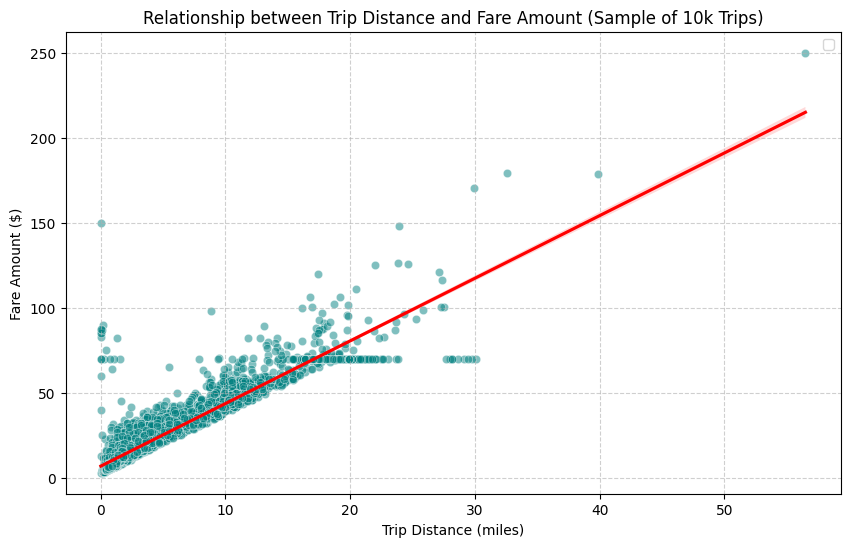

In [50]:
# Show how trip fare is affected by distance
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate Pearson correlation
correlation = df_filtered['trip_distance'].corr(df_filtered['fare_amount'])
print(f"Correlation between trip distance and fare amount: {correlation:.4f}")

# Create scatter plot (using a sample of 10,000 points for performance and clarity)
sample_df = df_filtered.sample(n=10000, random_state=42)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=sample_df, x='trip_distance', y='fare_amount', alpha=0.5, color='teal')
sns.regplot(data=sample_df, x='trip_distance', y='fare_amount', scatter=False, color='red', line_kws={'label': f'Trendline (r = {correlation:.2f})'})

plt.title('Relationship between Trip Distance and Fare Amount (Sample of 10k Trips)')
plt.xlabel('Trip Distance (miles)')
plt.ylabel('Fare Amount ($)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**3.1.7** <font color = red>[5 marks]</font> <br>
Find and visualise the correlation between:
1. `fare_amount` and trip duration (pickup time to dropoff time)
2. `fare_amount` and `passenger_count`
3. `tip_amount` and `trip_distance`

/tmp/ipykernel_1228/1338231970.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['trip_duration'] = (df_filtered['tpep_dropoff_datetime'] - df_filtered['tpep_pickup_datetime']).dt.total_seconds() / 60.0


Correlation between trip duration and fare amount: 0.8621


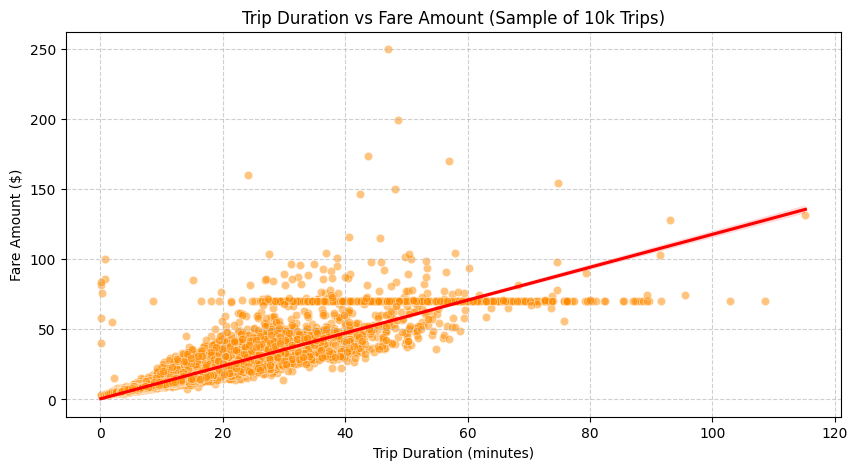

In [51]:
# Show relationship between fare and trip duration

# Calculate trip duration in minutes
df_filtered['trip_duration'] = (df_filtered['tpep_dropoff_datetime'] - df_filtered['tpep_pickup_datetime']).dt.total_seconds() / 60.0

# Filter out anomalies in duration (e.g. negative times or excessively long trips > 3 hours)
df_filtered_duration = df_filtered[(df_filtered['trip_duration'] > 0) & (df_filtered['trip_duration'] <= 180)]

# Calculate correlation
duration_corr = df_filtered_duration['trip_duration'].corr(df_filtered_duration['fare_amount'])
print(f"Correlation between trip duration and fare amount: {duration_corr:.4f}")

# Visualize relationship with a sampled scatter plot
sample_duration = df_filtered_duration.sample(n=10000, random_state=42)

plt.figure(figsize=(10, 5))
sns.scatterplot(data=sample_duration, x='trip_duration', y='fare_amount', alpha=0.5, color='darkorange')
sns.regplot(data=sample_duration, x='trip_duration', y='fare_amount', scatter=False, color='red')
plt.title('Trip Duration vs Fare Amount (Sample of 10k Trips)')
plt.xlabel('Trip Duration (minutes)')
plt.ylabel('Fare Amount ($)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Correlation between passenger count and fare amount: 0.0403


/tmp/ipykernel_1228/3320563691.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_filtered, x='passenger_count', y='fare_amount', palette='Set2')


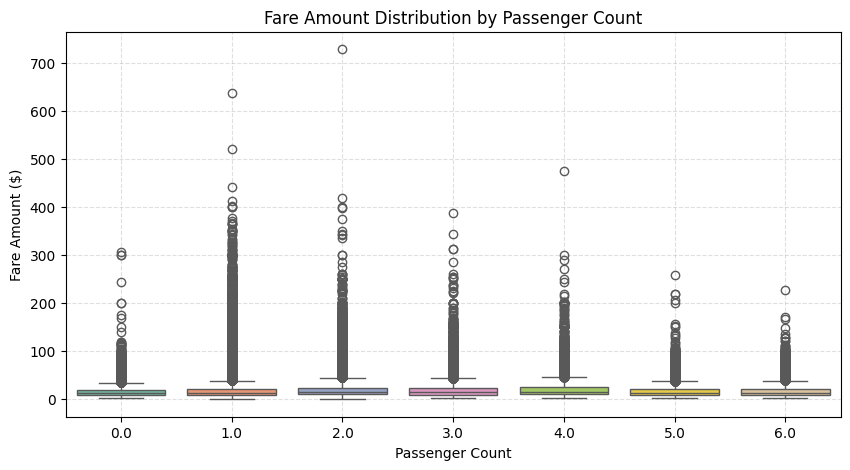

In [52]:
# Show relationship between fare and number of passengers

# Calculate correlation
passenger_corr = df_filtered['passenger_count'].corr(df_filtered['fare_amount'])
print(f"Correlation between passenger count and fare amount: {passenger_corr:.4f}")

# Visualize using a box plot since passenger count is discrete
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_filtered, x='passenger_count', y='fare_amount', palette='Set2')
plt.title('Fare Amount Distribution by Passenger Count')
plt.xlabel('Passenger Count')
plt.ylabel('Fare Amount ($)')
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

Correlation between trip distance and tip amount: 0.7991


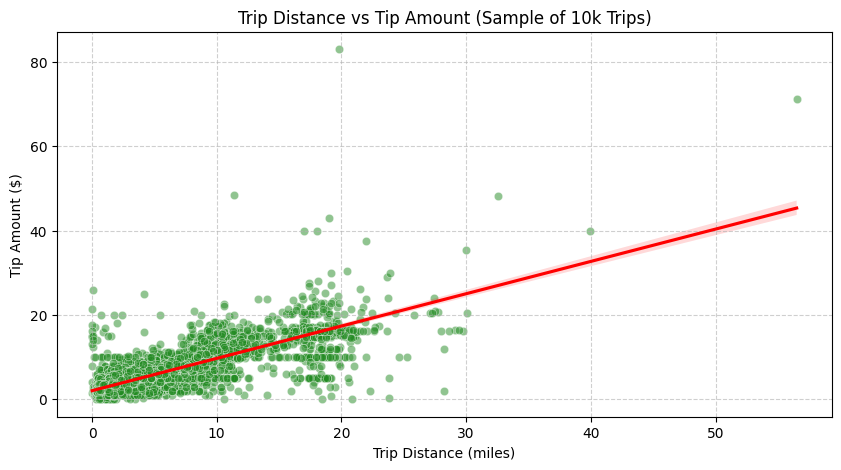

In [53]:
# Show relationship between tip and trip distance

# Calculate correlation
tip_distance_corr = df_filtered['trip_distance'].corr(df_filtered['tip_amount'])
print(f"Correlation between trip distance and tip amount: {tip_distance_corr:.4f}")

# Visualize using a sampled scatter plot
sample_tip = df_filtered.sample(n=10000, random_state=42)

plt.figure(figsize=(10, 5))
sns.scatterplot(data=sample_tip, x='trip_distance', y='tip_amount', alpha=0.5, color='forestgreen')
sns.regplot(data=sample_tip, x='trip_distance', y='tip_amount', scatter=False, color='red')
plt.title('Trip Distance vs Tip Amount (Sample of 10k Trips)')
plt.xlabel('Trip Distance (miles)')
plt.ylabel('Tip Amount ($)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**3.1.8** <font color = red>[3 marks]</font> <br>
Analyse the distribution of different payment types (`payment_type`)

--- Payment Type Distribution ---
Credit card    :  1412859 (100.00%)
Cash           :       23 (  0.00%)
Dispute        :       16 (  0.00%)
No charge      :        7 (  0.00%)


/tmp/ipykernel_1228/2074965878.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=payment_counts.values, y=payment_counts.index, palette='viridis')


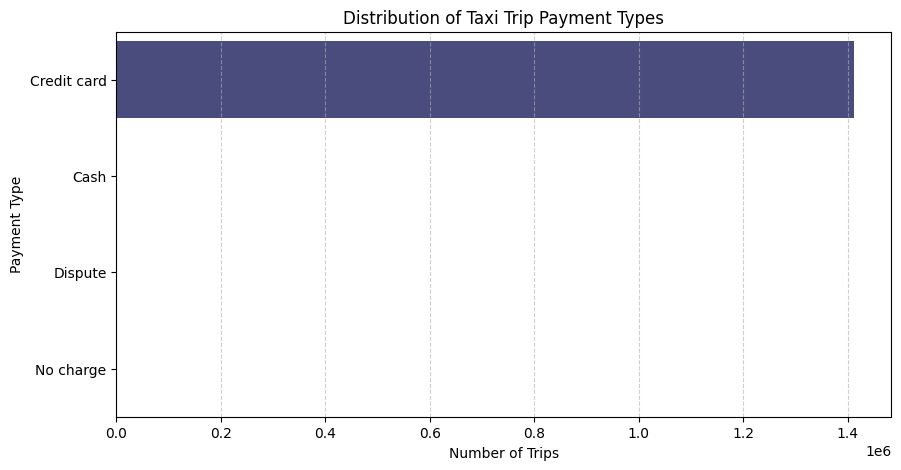

In [54]:
# Analyze the distribution of different payment types (payment_type)
import matplotlib.pyplot as plt
import seaborn as sns

# Map numerical codes to meaningful labels according to the dictionary
payment_labels = {
    1: 'Credit card',
    2: 'Cash',
    3: 'No charge',
    4: 'Dispute',
    5: 'Unknown',
    6: 'Voided trip'
}

# Create a copy and map payment types
df_payment = df_filtered.copy()
df_payment['payment_label'] = df_payment['payment_type'].map(payment_labels)

# Calculate counts and percentages
payment_counts = df_payment['payment_label'].value_counts()
payment_percent = df_payment['payment_label'].value_counts(normalize=True) * 100

print("--- Payment Type Distribution ---")
for idx in payment_counts.index:
    print(f"{idx:15}: {payment_counts[idx]:8d} ({payment_percent[idx]:6.2f}%)")

# Visualize payment type distribution
plt.figure(figsize=(10, 5))
sns.barplot(x=payment_counts.values, y=payment_counts.index, palette='viridis')
plt.title('Distribution of Taxi Trip Payment Types')
plt.xlabel('Number of Trips')
plt.ylabel('Payment Type')
plt.grid(True, axis='x', linestyle='--', alpha=0.6)
plt.show()

- 1= Credit card
- 2= Cash
- 3= No charge
- 4= Dispute



##### Geographical Analysis

For this, you have to use the *taxi_zones.shp* file from the *taxi_zones* folder.

There would be multiple files inside the folder (such as *.shx, .sbx, .sbn* etc). You do not need to import/read any of the files other than the shapefile, *taxi_zones.shp*.

Do not change any folder structure - all the files need to be present inside the folder for it to work.

The folder structure should look like this:
```
Taxi Zones
|- taxi_zones.shp.xml
|- taxi_zones.prj
|- taxi_zones.sbn
|- taxi_zones.shp
|- taxi_zones.dbf
|- taxi_zones.shx
|- taxi_zones.sbx

 ```

 You only need to read the `taxi_zones.shp` file. The *shp* file will utilise the other files by itself.

We will use the *GeoPandas* library for geopgraphical analysis
```
import geopandas as gpd
```

More about geopandas and shapefiles: [About](https://geopandas.org/en/stable/about.html)


Reading the shapefile is very similar to *Pandas*. Use `gpd.read_file()` function to load the data (*taxi_zones.shp*) as a GeoDataFrame. Documentation: [Reading and Writing Files](https://geopandas.org/en/stable/docs/user_guide/io.html)

In [55]:
# !pip install geopandas

**3.1.9** <font color = red>[2 marks]</font> <br>
Load the shapefile and display it.

In [56]:
# import geopandas as gpd

# Read the shapefile using geopandas

import geopandas as gpd
import zipfile
import os

# Define paths
zip_path = '/content/drive/MyDrive/Datasets and Dictionary-NYC.zip'
extract_path = '/content/taxi_zones_extracted'

# Extract the taxi_zones folder if not already done
if not os.path.exists(extract_path):
    with zipfile.ZipFile(zip_path, 'r') as archive:
        # Find all files inside the taxi_zones subdirectory
        zone_files = [f for f in archive.namelist() if 'taxi_zones' in f]
        for file in zone_files:
            archive.extract(file, extract_path)

# Locate the shapefile path
# Look for taxi_zones.shp recursively within extracted directory
shapefile_path = None
for root, dirs, files in os.walk(extract_path):
    for file in files:
        if file.endswith('.shp'):
            shapefile_path = os.path.join(root, file)
            break

if shapefile_path:
    print(f"Loading shapefile from: {shapefile_path}")
    zones = gpd.read_file(shapefile_path)
    print("Shapefile loaded successfully!")
    display(zones.head())
else:
    print("Error: Could not locate taxi_zones.shp inside the extracted zip directory.")

Loading shapefile from: /content/taxi_zones_extracted/Datasets and Dictionary/taxi_zones/taxi_zones.shp
Shapefile loaded successfully!


,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry
0,1,0.116357,0.000782,Newark Airport,1,EWR,"POLYGON ((933100.918 192536.086, 933091.011 19..."
1,2,0.433470,0.004866,Jamaica Bay,2,Queens,"MULTIPOLYGON (((1033269.244 172126.008, 103343..."
2,3,0.084341,0.000314,Allerton/Pelham Gardens,3,Bronx,"POLYGON ((1026308.77 256767.698, 1026495.593 2..."
3,4,0.043567,0.000112,Alphabet City,4,Manhattan,"POLYGON ((992073.467 203714.076, 992068.667 20..."
4,5,0.092146,0.000498,Arden Heights,5,Staten Island,"POLYGON ((935843.31 144283.336, 936046.565 144..."


Now, if you look at the DataFrame created, you will see columns like: `OBJECTID`,`Shape_Leng`, `Shape_Area`, `zone`, `LocationID`, `borough`, `geometry`.
<br><br>

Now, the `locationID` here is also what we are using to mark pickup and drop zones in the trip records.

The geometric parameters like shape length, shape area and geometry are used to plot the zones on a map.

This can be easily done using the `plot()` method.

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 263 entries, 0 to 262
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   OBJECTID    263 non-null    int32   
 1   Shape_Leng  263 non-null    float64 
 2   Shape_Area  263 non-null    float64 
 3   zone        263 non-null    object  
 4   LocationID  263 non-null    int32   
 5   borough     263 non-null    object  
 6   geometry    263 non-null    geometry
dtypes: float64(2), geometry(1), int32(2), object(2)
memory usage: 12.5+ KB
None


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

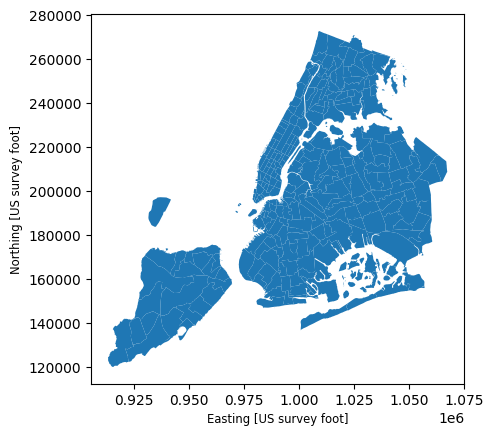

In [57]:
print(zones.info())
zones.plot()

Now, you have to merge the trip records and zones data using the location IDs.



**3.1.10** <font color = red>[3 marks]</font> <br>
Merge the zones data into trip data using the `locationID` and `PULocationID` columns.

In [58]:
# Merge zones and trip records using locationID and PULocationID
# Ensure LocationID is of the same type in both datasets before merging
zones['LocationID'] = zones['LocationID'].astype(int)
df_filtered['PULocationID'] = df_filtered['PULocationID'].astype(int)

# Perform the merge
# We will do a merge on the filtered trip records to get corresponding zone information for each pickup location
trips_with_zones = df_filtered.merge(zones, left_on='PULocationID', right_on='LocationID', how='inner')

print("Merge complete!")
print(f"Trips with zone details size: {trips_with_zones.shape}")
display(trips_with_zones[['tpep_pickup_datetime', 'PULocationID', 'zone', 'borough', 'total_amount']].head())

/tmp/ipykernel_1228/1743087792.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['PULocationID'] = df_filtered['PULocationID'].astype(int)


Merge complete!
Trips with zone details size: (1400479, 29)


,tpep_pickup_datetime,PULocationID,zone,borough,total_amount
0,2023-09-01 00:19:27,132,JFK Airport,Queens,98.40
1,2023-09-01 00:11:38,144,Little Italy/NoLiTa,Manhattan,14.90
2,2023-09-01 00:41:08,79,East Village,Manhattan,28.92
3,2023-09-01 00:07:47,48,Clinton East,Manhattan,20.52
4,2023-09-01 00:46:19,233,UN/Turtle Bay South,Manhattan,37.32


**3.1.11** <font color = red>[3 marks]</font> <br>
Group data by location IDs to find the total number of trips per location ID

In [59]:
# Group data by location and calculate the number of trips
trip_counts = trips_with_zones.groupby('PULocationID').size().reset_index(name='total_trips')

print("--- Top 10 Busiest Pickup Locations ---")
display(trip_counts.sort_values(by='total_trips', ascending=False).head(10))

--- Top 10 Busiest Pickup Locations ---


,PULocationID,total_trips
198,237,69858
133,161,67730
197,236,63695
108,132,63639
134,162,52690
114,138,51617
117,142,48921
154,186,48583
191,230,44372
142,170,43163


**3.1.12** <font color = red>[2 marks]</font> <br>
Now, use the grouped data to add number of trips to the GeoDataFrame.

We will use this to plot a map of zones showing total trips per zone.

In [60]:
# Merge trip counts back to the zones GeoDataFrame
zones_with_trips = zones.merge(trip_counts, left_on='LocationID', right_on='PULocationID', how='left')

# Fill NaN values for zones with no trips with 0
zones_with_trips['total_trips'] = zones_with_trips['total_trips'].fillna(0)

print("Merge complete!")
print(f"Zones GeoDataFrame now contains 'total_trips' column. Sample data:")
display(zones_with_trips[['LocationID', 'zone', 'borough', 'total_trips']].sort_values(by='total_trips', ascending=False).head(10))

Merge complete!
Zones GeoDataFrame now contains 'total_trips' column. Sample data:


,LocationID,zone,borough,total_trips
236,237,Upper East Side South,Manhattan,69858.0
160,161,Midtown Center,Manhattan,67730.0
235,236,Upper East Side North,Manhattan,63695.0
131,132,JFK Airport,Queens,63639.0
161,162,Midtown East,Manhattan,52690.0
137,138,LaGuardia Airport,Queens,51617.0
141,142,Lincoln Square East,Manhattan,48921.0
185,186,Penn Station/Madison Sq West,Manhattan,48583.0
229,230,Times Sq/Theatre District,Manhattan,44372.0
169,170,Murray Hill,Manhattan,43163.0


The next step is creating a color map (choropleth map) showing zones by the number of trips taken.

Again, you can use the `zones.plot()` method for this. [Plot Method GPD](https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoDataFrame.plot.html#geopandas.GeoDataFrame.plot)

But first, you need to define the figure and axis for the plot.

`fig, ax = plt.subplots(1, 1, figsize = (12, 10))`

This function creates a figure (fig) and a single subplot (ax)

---

After setting up the figure and axis, we can proceed to plot the GeoDataFrame on this axis. This is done in the next step where we use the plot method of the GeoDataFrame.

You can define the following parameters in the `zones.plot()` method:
```
column = '',
ax = ax,
legend = True,
legend_kwds = {'label': "label", 'orientation': "<horizontal/vertical>"}
```

To display the plot, use `plt.show()`.

**3.1.13** <font color = red>[3 marks]</font> <br>
Plot a color-coded map showing zone-wise trips

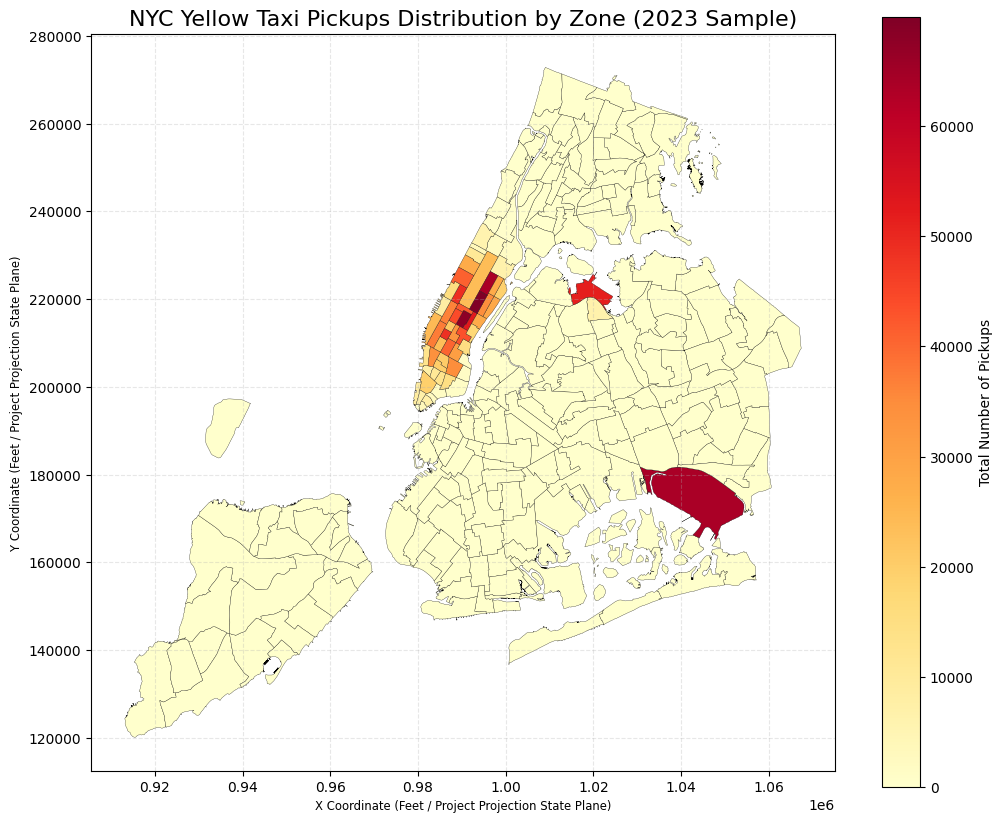

In [61]:
# Define figure and axis
fig, ax = plt.subplots(1, 1, figsize=(12, 10))

# Plot the map and display it
# We will plot using 'total_trips' as our target column and map with a vibrant colormap like 'YlOrRd'
zones_with_trips.plot(
    column='total_trips',
    ax=ax,
    legend=True,
    legend_kwds={'label': 'Total Number of Pickups', 'orientation': 'vertical'},
    cmap='YlOrRd',
    edgecolor='black',
    linewidth=0.2
)

plt.title('NYC Yellow Taxi Pickups Distribution by Zone (2023 Sample)', fontsize=16)
plt.xlabel('X Coordinate (Feet / Project Projection State Plane)')
plt.ylabel('Y Coordinate (Feet / Project Projection State Plane)')
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

In [62]:
# Display the zones sorted by the number of trips
sorted_zones = zones_with_trips[['LocationID', 'zone', 'borough', 'total_trips']].sort_values(by='total_trips', ascending=False)
display(sorted_zones.head(15))

,LocationID,zone,borough,total_trips
236,237,Upper East Side South,Manhattan,69858.0
160,161,Midtown Center,Manhattan,67730.0
235,236,Upper East Side North,Manhattan,63695.0
131,132,JFK Airport,Queens,63639.0
161,162,Midtown East,Manhattan,52690.0
137,138,LaGuardia Airport,Queens,51617.0
141,142,Lincoln Square East,Manhattan,48921.0
185,186,Penn Station/Madison Sq West,Manhattan,48583.0
229,230,Times Sq/Theatre District,Manhattan,44372.0
169,170,Murray Hill,Manhattan,43163.0


Here we have completed the temporal, financial and geographical analysis on the trip records.

**Compile your findings from general analysis below:**

You can consider the following points:

* Busiest hours, days and months
* Trends in revenue collected
* Trends in quarterly revenue
* How fare depends on trip distance, trip duration and passenger counts
* How tip amount depends on trip distance
* Busiest zones


#### **3.2** Detailed EDA: Insights and Strategies
<font color = red>[50 marks]</font> <br>

Having performed basic analyses for finding trends and patterns, we will now move on to some detailed analysis focussed on operational efficiency, pricing strategies, and customer experience.

##### Operational Efficiency

Analyze variations by time of day and location to identify bottlenecks or inefficiencies in routes

**3.2.1** <font color = red>[3 marks]</font> <br>
Identify slow routes by calculating the average time taken by cabs to get from one zone to another at different hours of the day.

Speed on a route *X* for hour *Y* = (*distance of the route X / average trip duration for hour Y*)

In [82]:
# Find routes which have the slowest speeds at different times of the day

# Speed = distance (miles) / average trip duration in hours
# Here we are taking slowest average speed

# Create a copy of the filtered dataset with the required duration column
df_speed = df_filtered.copy()

# Ensure duration in hours is calculated
df_speed['trip_duration_hours'] = df_speed['trip_duration'] / 60.0

# Group by pickup zone, dropoff zone, and hour to get average distance and average duration
route_groups = df_speed.groupby(['PULocationID', 'DOLocationID', 'pickup_hour']).agg(
    total_trips=('total_amount', 'count'),
    avg_distance=('trip_distance', 'mean'),
    avg_duration_hours=('trip_duration_hours', 'mean')
).reset_index()

# Only consider routes with a representative number of trips (e.g., at least 30 trips) to avoid single-trip outliers
route_groups = route_groups[route_groups['total_trips'] >= 30]

# Calculate average speed (miles per hour)
route_groups['avg_speed_mph'] = route_groups['avg_distance'] / route_groups['avg_duration_hours']

# Sort to find the slowest routes
slow_routes = route_groups.sort_values(by='avg_speed_mph', ascending=True)

# Merge with zones to get the names for pickup and dropoff locations
slow_routes = slow_routes.merge(zones[['LocationID', 'zone', 'borough']], left_on='PULocationID', right_on='LocationID')\
                         .rename(columns={'zone': 'pickup_zone', 'borough': 'pickup_borough'})\
                         .drop(columns=['LocationID'])

slow_routes = slow_routes.merge(zones[['LocationID', 'zone', 'borough']], left_on='DOLocationID', right_on='LocationID')\
                         .rename(columns={'zone': 'dropoff_zone', 'borough': 'dropoff_borough'})\
                         .drop(columns=['LocationID'])

print("--- Top 10 Slowest Common Taxi Routes in NYC ---")
display(slow_routes[['pickup_zone', 'dropoff_zone', 'pickup_hour', 'total_trips', 'avg_distance', 'avg_speed_mph']].sort_values(by='avg_speed_mph').head(10))

--- Top 10 Slowest Common Taxi Routes in NYC ---


,pickup_zone,dropoff_zone,pickup_hour,total_trips,avg_distance,avg_speed_mph
0,East Village,East Village,14,30,0.752333,0.853882
1,Clinton East,Times Sq/Theatre District,14,33,0.786364,0.895763
2,West Chelsea/Hudson Yards,Penn Station/Madison Sq West,22,30,0.967333,1.056468
3,Greenwich Village South,Greenwich Village North,17,38,0.763158,1.079148
4,Lincoln Square East,Lincoln Square East,23,42,0.720952,1.119305
5,Gramercy,Flatiron,13,33,0.980606,1.129921
6,TriBeCa/Civic Center,Battery Park City,15,38,0.874737,1.172395
7,Lincoln Square West,Clinton East,21,30,1.104667,1.201946
8,Flatiron,Gramercy,13,37,0.962432,1.202691
9,Clinton East,Midtown Center,16,41,0.989512,1.256145


How does identifying high-traffic, high-demand routes help us?

**3.2.2** <font color = red>[3 marks]</font> <br>
Calculate the number of trips at each hour of the day and visualise them. Find the busiest hour and show the number of trips for that hour.

Busiest Hour (Sample): 18:00 with 103058 trips inside the sample.


/tmp/ipykernel_1228/928641912.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=hourly_trips, x='pickup_hour', y='trip_count', palette='plasma')


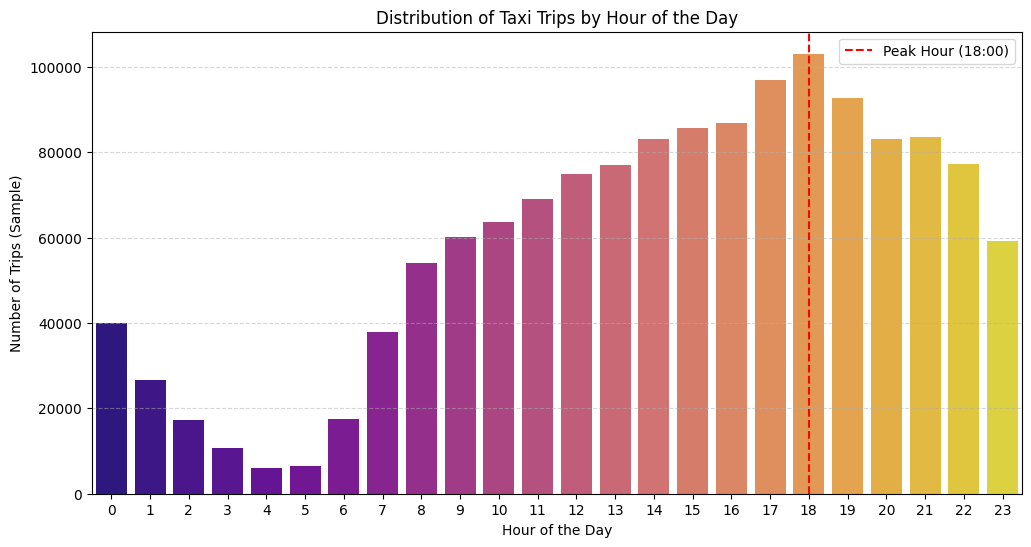

In [64]:
# Visualise the number of trips per hour and find the busiest hour

# Calculate trips per hour and visualize them
hourly_trips = df_filtered.groupby('pickup_hour').size().reset_index(name='trip_count')

# Find the busiest hour
busiest_hour_idx = hourly_trips['trip_count'].idxmax()
busiest_hour = hourly_trips.loc[busiest_hour_idx, 'pickup_hour']
busiest_trips_sample = hourly_trips.loc[busiest_hour_idx, 'trip_count']

print(f"Busiest Hour (Sample): {busiest_hour}:00 with {busiest_trips_sample} trips inside the sample.")

# Plot the hourly distribution
plt.figure(figsize=(12, 6))
sns.barplot(data=hourly_trips, x='pickup_hour', y='trip_count', palette='plasma')
plt.axvline(x=busiest_hour, color='red', linestyle='--', label=f'Peak Hour ({busiest_hour}:00)')
plt.title('Distribution of Taxi Trips by Hour of the Day')
plt.xlabel('Hour of the Day')
plt.ylabel('Number of Trips (Sample)')
plt.legend()
plt.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.show()

Remember, we took a fraction of trips. To find the actual number, you have to scale the number up by the sampling ratio.

**3.2.3** <font color = red>[2 mark]</font> <br>
Find the actual number of trips in the five busiest hours

In [65]:
# Scale up the number of trips

# Fill in the value of your sampling fraction and use that to scale up the numbers

# To find the actual estimated volumes for the top 5 busiest hours

# Define the sampling fraction used during our data preparation
sample_fraction = 0.05
scaling_factor = 1.0 / sample_fraction

# Get the top 5 busiest hours from our hourly trip counts
top_5_hours = hourly_trips.sort_values(by='trip_count', ascending=False).head(5).copy()

# Calculate estimated actual trips
top_5_hours['estimated_actual_trips'] = (top_5_hours['trip_count'] * scaling_factor).astype(int)

print(f"--- Top 5 Busiest Hours & Estimated Actual Trip Volumes (Scaling Factor: {scaling_factor}x) ---")
display(top_5_hours.rename(columns={
    'pickup_hour': 'Hour of Day',
    'trip_count': 'Sample Trip Count',
    'estimated_actual_trips': 'Estimated Actual Trips'
}))

--- Top 5 Busiest Hours & Estimated Actual Trip Volumes (Scaling Factor: 20.0x) ---


,Hour of Day,Sample Trip Count,Estimated Actual Trips
18,18,103058,2061160
17,17,96953,1939060
19,19,92730,1854600
16,16,86834,1736680
15,15,85665,1713300


**3.2.4** <font color = red>[3 marks]</font> <br>
Compare hourly traffic pattern on weekdays. Also compare for weekend.

/tmp/ipykernel_1228/325858798.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['day_of_week'] = df_filtered['tpep_pickup_datetime'].dt.dayofweek
/tmp/ipykernel_1228/325858798.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['day_type'] = df_filtered['day_of_week'].apply(lambda x: 'Weekend' if x >= 5 else 'Weekday')


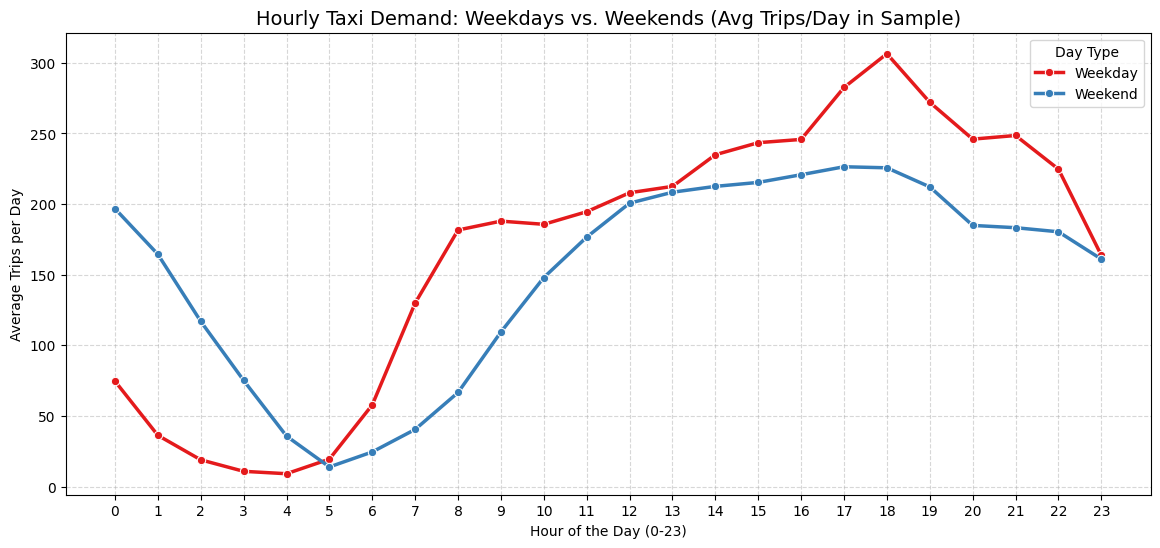

In [66]:
# Compare traffic trends for the weekdays and weekends

# 1. Create a helper column to flag Weekdays vs Weekends
# Monday=0, Sunday=6. Weekday is 0-4, Weekend is 5-6.
df_filtered['day_of_week'] = df_filtered['tpep_pickup_datetime'].dt.dayofweek
df_filtered['day_type'] = df_filtered['day_of_week'].apply(lambda x: 'Weekend' if x >= 5 else 'Weekday')

# 2. Group by Day Type and Hour
hourly_day_type = df_filtered.groupby(['day_type', 'pickup_hour']).size().reset_index(name='trip_count')

# 3. Pivot or normalize counts for side-by-side comparison
# Since there are 5 weekdays and only 2 weekend days, we scale/average them to show average trips per day type hour
weekday_days_count = df_filtered[df_filtered['day_type'] == 'Weekday']['tpep_pickup_datetime'].dt.date.nunique()
weekend_days_count = df_filtered[df_filtered['day_type'] == 'Weekend']['tpep_pickup_datetime'].dt.date.nunique()

# Map days counts to calculate average trips per single day
hourly_day_type['avg_trips_per_day'] = hourly_day_type.apply(
    lambda row: row['trip_count'] / weekday_days_count if row['day_type'] == 'Weekday'
    else row['trip_count'] / weekend_days_count, axis=1
)

# 4. Plot the comparison
plt.figure(figsize=(14, 6))
sns.lineplot(data=hourly_day_type, x='pickup_hour', y='avg_trips_per_day', hue='day_type', marker='o', linewidth=2.5, palette='Set1')
plt.title('Hourly Taxi Demand: Weekdays vs. Weekends (Avg Trips/Day in Sample)', fontsize=14)
plt.xlabel('Hour of the Day (0-23)')
plt.ylabel('Average Trips per Day')
plt.xticks(range(24))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Day Type')
plt.show()

What can you infer from the above patterns? How will finding busy and quiet hours for each day help us?

**3.2.5** <font color = red>[3 marks]</font> <br>
Identify top 10 zones with high hourly pickups. Do the same for hourly dropoffs. Show pickup and dropoff trends in these zones.

In [67]:
# Find top 10 pickup and dropoff zones

# 1. Identify top 10 pickup zones
top_pickups = df_filtered.groupby('PULocationID').size().reset_index(name='pickup_count')
top_pickups = top_pickups.sort_values(by='pickup_count', ascending=False).head(10)
top_pickups_named = top_pickups.merge(zones[['LocationID', 'zone', 'borough']], left_on='PULocationID', right_on='LocationID', how='inner')

# 2. Identify top 10 dropoff zones
top_dropoffs = df_filtered.groupby('DOLocationID').size().reset_index(name='dropoff_count')
top_dropoffs = top_dropoffs.sort_values(by='dropoff_count', ascending=False).head(10)
top_dropoffs_named = top_dropoffs.merge(zones[['LocationID', 'zone', 'borough']], left_on='DOLocationID', right_on='LocationID', how='inner')

print("--- TOP 10 PICKUP ZONES ---")
display(top_pickups_named[['PULocationID', 'zone', 'borough', 'pickup_count']])

print("\n--- TOP 10 DROPOFF ZONES ---")
display(top_dropoffs_named[['DOLocationID', 'zone', 'borough', 'dropoff_count']])

--- TOP 10 PICKUP ZONES ---


,PULocationID,zone,borough,pickup_count
0,237,Upper East Side South,Manhattan,69858
1,161,Midtown Center,Manhattan,67730
2,236,Upper East Side North,Manhattan,63695
3,132,JFK Airport,Queens,63639
4,162,Midtown East,Manhattan,52690
5,138,LaGuardia Airport,Queens,51617
6,142,Lincoln Square East,Manhattan,48921
7,186,Penn Station/Madison Sq West,Manhattan,48583
8,230,Times Sq/Theatre District,Manhattan,44372
9,170,Murray Hill,Manhattan,43163



--- TOP 10 DROPOFF ZONES ---


,DOLocationID,zone,borough,dropoff_count
0,236,Upper East Side North,Manhattan,67479
1,237,Upper East Side South,Manhattan,62507
2,161,Midtown Center,Manhattan,55370
3,170,Murray Hill,Manhattan,43202
4,239,Upper West Side South,Manhattan,42713
5,142,Lincoln Square East,Manhattan,41487
6,162,Midtown East,Manhattan,41353
7,141,Lenox Hill West,Manhattan,39774
8,230,Times Sq/Theatre District,Manhattan,39308
9,68,East Chelsea,Manhattan,36097


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


**3.2.6** <font color = red>[3 marks]</font> <br>
Find the ratio of pickups and dropoffs in each zone. Display the 10 highest (pickup/drop) and 10 lowest (pickup/drop) ratios.

In [68]:
# Find the top 10 and bottom 10 pickup/dropoff ratios

# 1. Get pickup counts per zone
pickups_per_zone = df_filtered.groupby('PULocationID').size().reset_index(name='pickups')

# 2. Get dropoff counts per zone
dropoffs_per_zone = df_filtered.groupby('DOLocationID').size().reset_index(name='dropoffs')

# 3. Merge counts together
ratio_df = pickups_per_zone.merge(dropoffs_per_zone, left_on='PULocationID', right_on='DOLocationID', how='outer')
ratio_df.rename(columns={'PULocationID': 'LocationID'}, inplace=True)
ratio_df.drop(columns=['DOLocationID'], inplace=True, errors='ignore')

# Fill missing values with 0
ratio_df['pickups'] = ratio_df['pickups'].fillna(0)
ratio_df['dropoffs'] = ratio_df['dropoffs'].fillna(0)

# Only analyze zones with substantial traffic (e.g. at least 100 pickups and 100 dropoffs to avoid extreme division ratio anomalies)
active_ratio_df = ratio_df[(ratio_df['pickups'] >= 100) & (ratio_df['dropoffs'] >= 100)].copy()

# Calculate Pickup/Dropoff ratio
active_ratio_df['pickup_dropoff_ratio'] = active_ratio_df['pickups'] / active_ratio_df['dropoffs']

# Merge with zones data to get names
active_ratio_named = active_ratio_df.merge(zones[['LocationID', 'zone', 'borough']], on='LocationID', how='inner')

# Sort
top_10_ratios = active_ratio_named.sort_values(by='pickup_dropoff_ratio', ascending=False).head(10)
bottom_10_ratios = active_ratio_named.sort_values(by='pickup_dropoff_ratio', ascending=True).head(10)

print("--- 10 HIGHEST PICKUP-TO-DROPOFF RATIOS (Passenger Exporters) ---")
display(top_10_ratios[['LocationID', 'zone', 'borough', 'pickups', 'dropoffs', 'pickup_dropoff_ratio']])

print("\n--- 10 LOWEST PICKUP-TO-DROPOFF RATIOS (Passenger Importers) ---")
display(bottom_10_ratios[['LocationID', 'zone', 'borough', 'pickups', 'dropoffs', 'pickup_dropoff_ratio']])

--- 10 HIGHEST PICKUP-TO-DROPOFF RATIOS (Passenger Exporters) ---


,LocationID,zone,borough,pickups,dropoffs,pickup_dropoff_ratio
19,70.0,East Elmhurst,Queens,6402.0,462.0,13.857143
37,132.0,JFK Airport,Queens,63639.0,13430.0,4.738570
39,138.0,LaGuardia Airport,Queens,51617.0,17977.0,2.871280
58,186.0,Penn Station/Madison Sq West,Manhattan,48583.0,29442.0,1.650126
11,43.0,Central Park,Manhattan,23917.0,17235.0,1.387699
33,114.0,Greenwich Village South,Manhattan,19825.0,14340.0,1.382497
78,249.0,West Village,Manhattan,33898.0,25470.0,1.330899
52,162.0,Midtown East,Manhattan,52690.0,41353.0,1.274152
51,161.0,Midtown Center,Manhattan,67730.0,55370.0,1.223226
29,100.0,Garment District,Manhattan,21362.0,17502.0,1.220546



--- 10 LOWEST PICKUP-TO-DROPOFF RATIOS (Passenger Importers) ---


,LocationID,zone,borough,pickups,dropoffs,pickup_dropoff_ratio
31,112.0,Greenpoint,Brooklyn,125.0,3293.0,0.037959
57,181.0,Park Slope,Brooklyn,265.0,3964.0,0.066852
1,7.0,Astoria,Queens,253.0,3475.0,0.072806
80,256.0,Williamsburg (South Side),Brooklyn,264.0,3247.0,0.081306
63,223.0,Steinway,Queens,139.0,1650.0,0.084242
79,255.0,Williamsburg (North Side),Brooklyn,356.0,4053.0,0.087836
36,129.0,Jackson Heights,Queens,117.0,1274.0,0.091837
23,80.0,East Williamsburg,Brooklyn,169.0,1820.0,0.092857
8,40.0,Carroll Gardens,Brooklyn,130.0,1391.0,0.093458
10,42.0,Central Harlem North,Manhattan,352.0,3741.0,0.094092


**3.2.7** <font color = red>[3 marks]</font> <br>
Identify zones with high pickup and dropoff traffic during night hours (11PM to 5AM)

In [69]:
# During night hours (11pm to 5am) find the top 10 pickup and dropoff zones
# Note that the top zones should be of night hours and not the overall top zones

# 1. Filter for night hours (11 PM [23] to 5 AM [5])
# This means hour >= 23 or hour < 5
night_trips = df_filtered[(df_filtered['pickup_hour'] >= 23) | (df_filtered['pickup_hour'] < 5)].copy()

# 2. Get top 10 pickup zones at night
night_pickups = night_trips.groupby('PULocationID').size().reset_index(name='night_pickup_count')
night_pickups = night_pickups.sort_values(by='night_pickup_count', ascending=False).head(10)
night_pickups_named = night_pickups.merge(zones[['LocationID', 'zone', 'borough']], left_on='PULocationID', right_on='LocationID', how='inner')

# 3. Get top 10 dropoff zones at night
night_dropoffs = night_trips.groupby('DOLocationID').size().reset_index(name='night_dropoff_count')
night_dropoffs = night_dropoffs.sort_values(by='night_dropoff_count', ascending=False).head(10)
night_dropoffs_named = night_dropoffs.merge(zones[['LocationID', 'zone', 'borough']], left_on='DOLocationID', right_on='LocationID', how='inner')

print("--- TOP 10 NIGHTTIME PICKUP ZONES (11 PM - 5 AM) ---")
display(night_pickups_named[['PULocationID', 'zone', 'borough', 'night_pickup_count']])

print("\n--- TOP 10 NIGHTTIME DROPOFF ZONES (11 PM - 5 AM) ---")
display(night_dropoffs_named[['DOLocationID', 'zone', 'borough', 'night_dropoff_count']])

--- TOP 10 NIGHTTIME PICKUP ZONES (11 PM - 5 AM) ---


,PULocationID,zone,borough,night_pickup_count
0,79,East Village,Manhattan,12694
1,249,West Village,Manhattan,10414
2,132,JFK Airport,Queens,8797
3,148,Lower East Side,Manhattan,7944
4,48,Clinton East,Manhattan,7630
5,114,Greenwich Village South,Manhattan,7259
6,230,Times Sq/Theatre District,Manhattan,5594
7,186,Penn Station/Madison Sq West,Manhattan,4860
8,138,LaGuardia Airport,Queens,4667
9,164,Midtown South,Manhattan,4667



--- TOP 10 NIGHTTIME DROPOFF ZONES (11 PM - 5 AM) ---


,DOLocationID,zone,borough,night_dropoff_count
0,79,East Village,Manhattan,6701
1,48,Clinton East,Manhattan,4984
2,170,Murray Hill,Manhattan,4918
3,107,Gramercy,Manhattan,4769
4,141,Lenox Hill West,Manhattan,4360
5,68,East Chelsea,Manhattan,4276
6,263,Yorkville West,Manhattan,4161
7,249,West Village,Manhattan,4097
8,239,Upper West Side South,Manhattan,3663
9,229,Sutton Place/Turtle Bay North,Manhattan,3586


Now, let us find the revenue share for the night time hours and the day time hours. After this, we will move to deciding a pricing strategy.

**3.2.8** <font color = red>[2 marks]</font> <br>
Find the revenue share for nighttime and daytime hours.

In [70]:
# Filter for night hours (11 PM to 5 AM)
night_trips = df_filtered[(df_filtered['pickup_hour'] >= 23) | (df_filtered['pickup_hour'] < 5)].copy()

# 1. Filter for daytime hours (5 AM to 11 PM)
day_trips = df_filtered[(df_filtered['pickup_hour'] >= 5) & (df_filtered['pickup_hour'] < 23)].copy()

# 2. Calculate revenues
night_revenue = night_trips['total_amount'].sum()
day_revenue = day_trips['total_amount'].sum()
total_revenue = df_filtered['total_amount'].sum()

# 3. Calculate shares
night_share = (night_revenue / total_revenue) * 100
day_share = (day_revenue / total_revenue) * 100

print(f"--- REVENUE SHARE ANALYSIS ---")
print(f"Nighttime Revenue (11 PM - 5 AM): ${night_revenue:,.2f} ({night_share:.2f}%)")
print(f"Daytime Revenue (5 AM - 11 PM):   ${day_revenue:,.2f} ({day_share:.2f}%)")
print(f"Total Filtered Revenue:            ${total_revenue:,.2f}")

--- REVENUE SHARE ANALYSIS ---
Nighttime Revenue (11 PM - 5 AM): $4,714,746.85 (11.28%)
Daytime Revenue (5 AM - 11 PM):   $37,076,721.06 (88.72%)
Total Filtered Revenue:            $41,791,467.91


##### Pricing Strategy

**3.2.9** <font color = red>[2 marks]</font> <br>
For the different passenger counts, find the average fare per mile per passenger.

For instance, suppose the average fare per mile for trips with 3 passengers is 3 USD/mile, then the fare per mile per passenger will be 1 USD/mile.

--- Average Fare per Mile per Passenger by Passenger Count ---


,passenger_count,mean,median,std,count
0,1.0,7.551995,7.128713,2.630527,1061389
1,2.0,3.745970,3.472222,1.555345,209309
2,3.0,2.560470,2.368421,1.117094,50256
3,4.0,1.912326,1.758721,0.889453,25297
4,5.0,1.511300,1.409836,0.607849,18679
5,6.0,1.276837,1.190476,0.537637,12430


/tmp/ipykernel_1228/4151100527.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_fares_clean, x='passenger_count', y='fare_per_mile_per_passenger', palette='Set3')


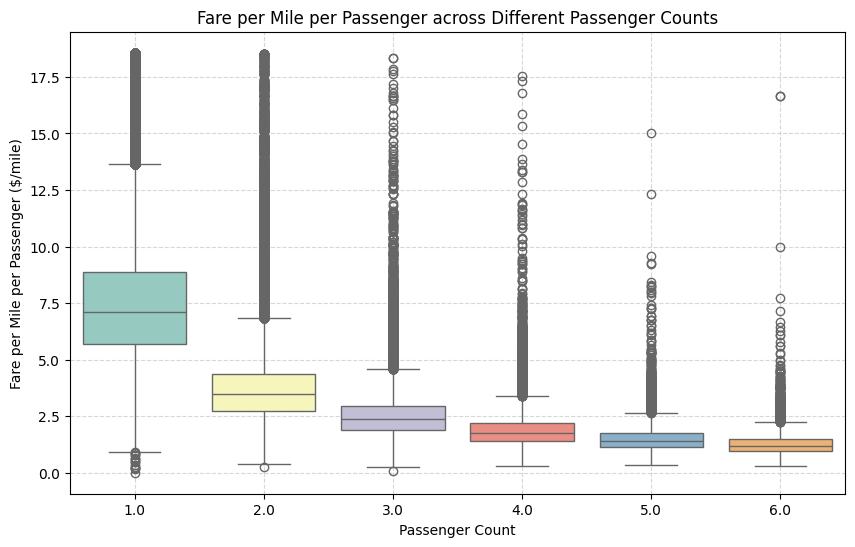

In [71]:
# Analyse the fare per mile per passenger for different passenger counts
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Filter out cases where passenger_count is 0 to avoid division by zero
df_fares = df_filtered[df_filtered['passenger_count'] > 0].copy()

# 2. Calculate fare per mile, and then divide by passenger count
df_fares['fare_per_mile'] = df_fares['fare_amount'] / df_fares['trip_distance']
df_fares['fare_per_mile_per_passenger'] = df_fares['fare_per_mile'] / df_fares['passenger_count']

# 3. Filter out potential infinite/extremely high outliers in fare_per_mile to get reliable statistical averages
# For example, extremely short distance trips can sometimes yield highly distorted rates per mile.
q_high = df_fares['fare_per_mile_per_passenger'].quantile(0.99)
df_fares_clean = df_fares[df_fares['fare_per_mile_per_passenger'] <= q_high]

# 4. Group by passenger count
passenger_fare_analysis = df_fares_clean.groupby('passenger_count')['fare_per_mile_per_passenger'].agg(['mean', 'median', 'std', 'count']).reset_index()

print("--- Average Fare per Mile per Passenger by Passenger Count ---")
display(passenger_fare_analysis)

# 5. Visualize with a boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_fares_clean, x='passenger_count', y='fare_per_mile_per_passenger', palette='Set3')
plt.title('Fare per Mile per Passenger across Different Passenger Counts')
plt.xlabel('Passenger Count')
plt.ylabel('Fare per Mile per Passenger ($/mile)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**3.2.10** <font color = red>[3 marks]</font> <br>
Find the average fare per mile by hours of the day and by days of the week

/tmp/ipykernel_1228/1941995999.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temporal_fare_clean['pickup_hour'] = df_temporal_fare_clean['tpep_pickup_datetime'].dt.hour
/tmp/ipykernel_1228/1941995999.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temporal_fare_clean['pickup_day_of_week'] = df_temporal_fare_clean['tpep_pickup_datetime'].dt.day_name()
/tmp/ipykernel_1228/1941995999.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .

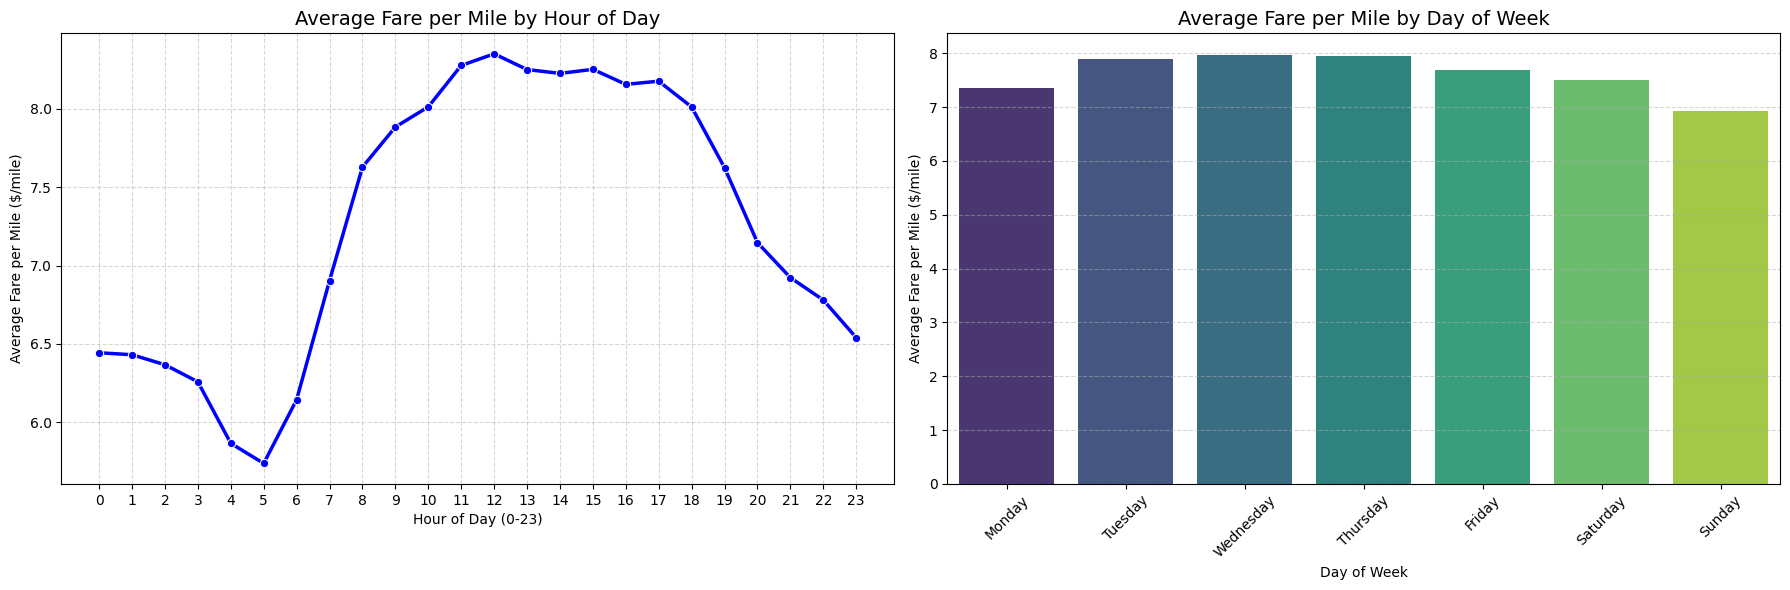

--- Average Fare per Mile by Day of Week ---


,pickup_day_of_week,fare_per_mile
0,Monday,7.346182
1,Tuesday,7.888990
2,Wednesday,7.972169
3,Thursday,7.955080
4,Friday,7.698302
5,Saturday,7.509064
6,Sunday,6.935475



--- Average Fare per Mile by Hour (Top 5 & Bottom 5 Hours) ---
Top 5 Hours (Most Expensive per Mile):


,pickup_hour,fare_per_mile
12,12,8.352282
11,11,8.277795
15,15,8.253082
13,13,8.251825
14,14,8.227312


Bottom 5 Hours (Cheapest per Mile):


,pickup_hour,fare_per_mile
2,2,6.367440
3,3,6.258223
6,6,6.144323
4,4,5.865634
5,5,5.737400


In [72]:
# Compare the average fare per mile for different days and for different times of the day
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Prepare data (use the cleaned master dataset 'df_loaded')
# Filter out 0 or negative distances & fares to prevent division by zero or skewed ratios
df_temporal_fare = df_loaded[(df_loaded['trip_distance'] > 0) & (df_loaded['fare_amount'] > 0)].copy()

# Calculate Fare per Mile
df_temporal_fare['fare_per_mile'] = df_temporal_fare['fare_amount'] / df_temporal_fare['trip_distance']

# Filter out extreme outliers (above 99th percentile) of fare_per_mile for reliable averages
q_fare_mile_high = df_temporal_fare['fare_per_mile'].quantile(0.99)
df_temporal_fare_clean = df_temporal_fare[df_temporal_fare['fare_per_mile'] <= q_fare_mile_high]

# 2. Extract day of week and hour
df_temporal_fare_clean['pickup_hour'] = df_temporal_fare_clean['tpep_pickup_datetime'].dt.hour
df_temporal_fare_clean['pickup_day_of_week'] = df_temporal_fare_clean['tpep_pickup_datetime'].dt.day_name()
df_temporal_fare_clean['day_num'] = df_temporal_fare_clean['tpep_pickup_datetime'].dt.dayofweek

# 3. Aggregate average fare per mile by hour
hourly_fare = df_temporal_fare_clean.groupby('pickup_hour')['fare_per_mile'].mean().reset_index()

# 4. Aggregate average fare per mile by day of week
daily_fare = df_temporal_fare_clean.groupby(['day_num', 'pickup_day_of_week'])['fare_per_mile'].mean().reset_index().sort_values('day_num')

# 5. Visualizations
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Plot Hourly Trend
sns.lineplot(ax=axes[0], data=hourly_fare, x='pickup_hour', y='fare_per_mile', marker='o', color='b', linewidth=2.5)
axes[0].set_title('Average Fare per Mile by Hour of Day', fontsize=14)
axes[0].set_xlabel('Hour of Day (0-23)')
axes[0].set_ylabel('Average Fare per Mile ($/mile)')
axes[0].set_xticks(range(24))
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot Daily Trend
sns.barplot(ax=axes[1], data=daily_fare, x='pickup_day_of_week', y='fare_per_mile', palette='viridis', hue='pickup_day_of_week', legend=False)
axes[1].set_title('Average Fare per Mile by Day of Week', fontsize=14)
axes[1].set_xlabel('Day of Week')
axes[1].set_ylabel('Average Fare per Mile ($/mile)')
axes[1].grid(True, axis='y', linestyle='--', alpha=0.5)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Print summary tables
print("--- Average Fare per Mile by Day of Week ---")
display(daily_fare[['pickup_day_of_week', 'fare_per_mile']])

print("\n--- Average Fare per Mile by Hour (Top 5 & Bottom 5 Hours) ---")
sorted_hours = hourly_fare.sort_values(by='fare_per_mile', ascending=False)
print("Top 5 Hours (Most Expensive per Mile):")
display(sorted_hours.head(5))
print("Bottom 5 Hours (Cheapest per Mile):")
display(sorted_hours.tail(5))

**3.2.11** <font color = red>[3 marks]</font> <br>
Analyse the average fare per mile for the different vendors for different hours of the day

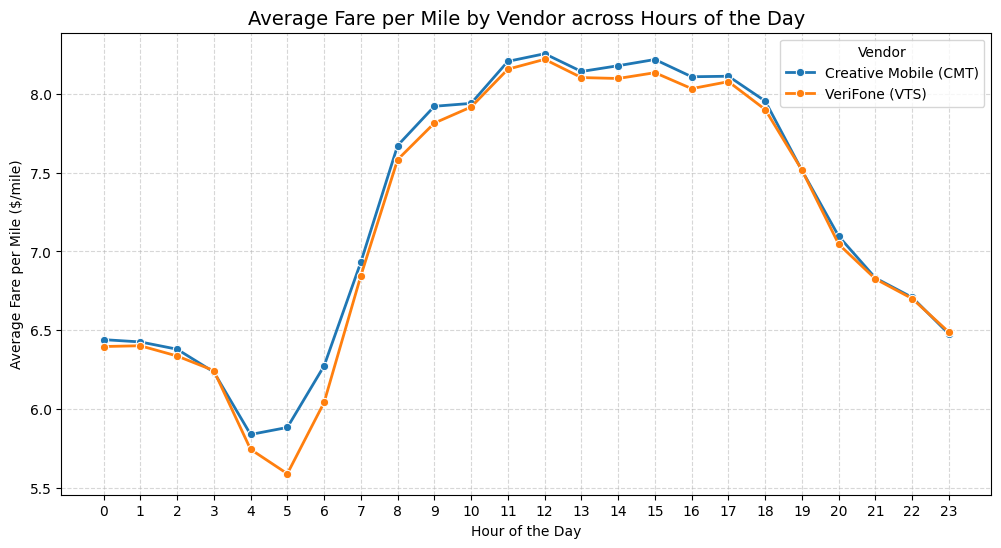

--- Overall Average Fare per Mile by Vendor ---


,mean,median,count
VendorID,,,
1,7.613465,7.133333,356964
2,7.519490,7.083333,1041811


In [73]:
# Compare fare per mile for different vendors
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Map VendorID representation if available; standard taxi dictionary: 1 = Creative Mobile, 2 = VeriFone
# Since 'VendorID' column was dropped from 'df_loaded', let's pull it back from the original master dataframe 'df'
if 'VendorID' not in df_filtered.columns and 'VendorID' in df:
    df_filtered = df_filtered.join(df['VendorID'], how='inner')

# Ensure clean, non-zero parameters
df_vendor_fare = df_filtered[(df_filtered['trip_distance'] > 0) & (df_filtered['fare_amount'] > 0)].copy()
df_vendor_fare['fare_per_mile'] = df_vendor_fare['fare_amount'] / df_vendor_fare['trip_distance']

# Remove extreme outliers to avoid skewing the mean
q_high = df_vendor_fare['fare_per_mile'].quantile(0.99)
df_vendor_clean = df_vendor_fare[df_vendor_fare['fare_per_mile'] <= q_high]

# Ensure pickup_hour column is present
if 'pickup_hour' not in df_vendor_clean.columns:
    df_vendor_clean['pickup_hour'] = df_vendor_clean['tpep_pickup_datetime'].dt.hour

# Group by VendorID and pickup_hour
vendor_hourly_analysis = df_vendor_clean.groupby(['VendorID', 'pickup_hour'])['fare_per_mile'].mean().reset_index()

# Map vendor names
vendor_map = {1: 'Creative Mobile (CMT)', 2: 'VeriFone (VTS)'}
vendor_hourly_analysis['Vendor'] = vendor_hourly_analysis['VendorID'].map(vendor_map).fillna(vendor_hourly_analysis['VendorID'])

# Plot the hourly fare per mile comparison
plt.figure(figsize=(12, 6))
sns.lineplot(data=vendor_hourly_analysis, x='pickup_hour', y='fare_per_mile', hue='Vendor', marker='o', linewidth=2)
plt.title('Average Fare per Mile by Vendor across Hours of the Day', fontsize=14)
plt.xlabel('Hour of the Day')
plt.ylabel('Average Fare per Mile ($/mile)')
plt.xticks(range(24))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Vendor')
plt.show()

# Display summary statistics
print("--- Overall Average Fare per Mile by Vendor ---")
display(df_vendor_clean.groupby('VendorID')['fare_per_mile'].agg(['mean', 'median', 'count']))

**3.2.12** <font color = red>[5 marks]</font> <br>
Compare the fare rates of the different vendors in a tiered fashion. Analyse the average fare per mile for distances upto 2 miles. Analyse the fare per mile for distances from 2 to 5 miles. And then for distances more than 5 miles.


/tmp/ipykernel_1228/4047343017.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_vendor_clean['distance_tier'] = df_vendor_clean['trip_distance'].apply(get_distance_tier)


--- Tiered Fare per Mile Analysis by Vendor ---


,VendorID,distance_tier,mean,median,count,Vendor
0,1,0-2 miles (Short),9.013839,8.333333,206355,Creative Mobile (CMT)
3,2,0-2 miles (Short),9.024406,8.437500,560105,VeriFone (VTS)
1,1,2-5 miles (Medium),6.351311,6.095238,97995,Creative Mobile (CMT)
4,2,2-5 miles (Medium),6.530570,6.253687,300799,VeriFone (VTS)
2,1,5+ miles (Long),4.471921,4.301724,52614,Creative Mobile (CMT)
5,2,5+ miles (Long),4.504431,4.324597,180907,VeriFone (VTS)


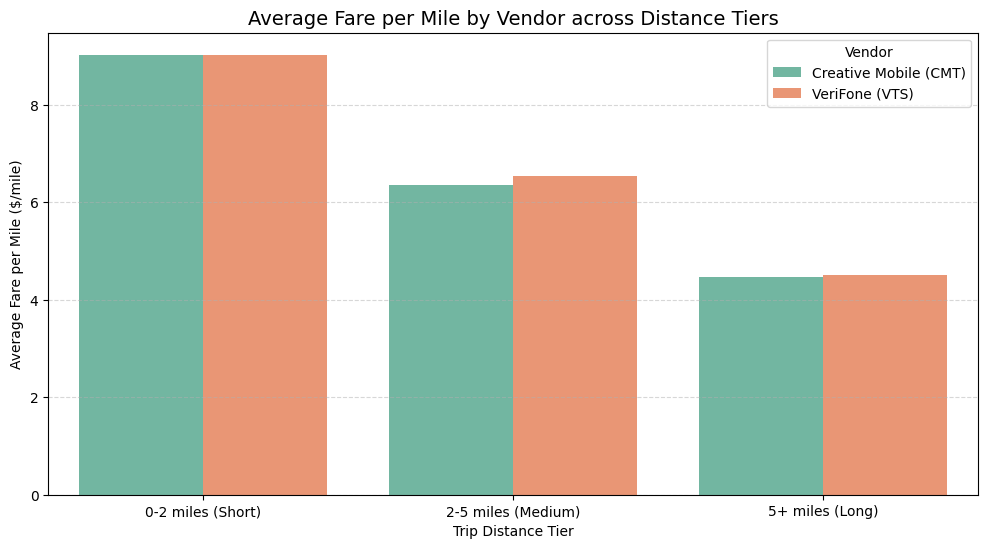

In [74]:
# Defining distance tiers

# Analyzing average fare per mile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define distance tiers in the cleaned vendor dataframe
def get_distance_tier(dist):
    if dist <= 2:
        return '0-2 miles (Short)'
    elif dist <= 5:
        return '2-5 miles (Medium)'
    else:
        return '5+ miles (Long)'

df_vendor_clean['distance_tier'] = df_vendor_clean['trip_distance'].apply(get_distance_tier)

# 2. Group by Vendor, Distance Tier, and calculate statistics
tiered_analysis = df_vendor_clean.groupby(['VendorID', 'distance_tier'])['fare_per_mile'].agg(['mean', 'median', 'count']).reset_index()

# Map vendor names for readability
vendor_map = {1: 'Creative Mobile (CMT)', 2: 'VeriFone (VTS)'}
tiered_analysis['Vendor'] = tiered_analysis['VendorID'].map(vendor_map).fillna(tiered_analysis['VendorID'])

print("--- Tiered Fare per Mile Analysis by Vendor ---")
display(tiered_analysis.sort_values(by=['distance_tier', 'VendorID']))

# 3. Visualize the comparison
plt.figure(figsize=(12, 6))
sns.barplot(data=tiered_analysis, x='distance_tier', y='mean', hue='Vendor', palette='Set2')
plt.title('Average Fare per Mile by Vendor across Distance Tiers', fontsize=14)
plt.xlabel('Trip Distance Tier')
plt.ylabel('Average Fare per Mile ($/mile)')
plt.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.legend(title='Vendor')
plt.show()

##### Customer Experience and Other Factors

**3.2.13** <font color = red>[5 marks]</font> <br>
Analyse average tip percentages based on trip distances, passenger counts and time of pickup. What factors lead to low tip percentages?

/tmp/ipykernel_1228/2411980841.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[0], data=tip_by_dist, x='distance_tier', y='tip_percent', palette='Greens_d', order=['Short (0-2 mi)', 'Medium (2-5 mi)', 'Long (5+ mi)'])
/tmp/ipykernel_1228/2411980841.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[1], data=tip_by_pass, x='passenger_count', y='tip_percent', palette='Blues_d')


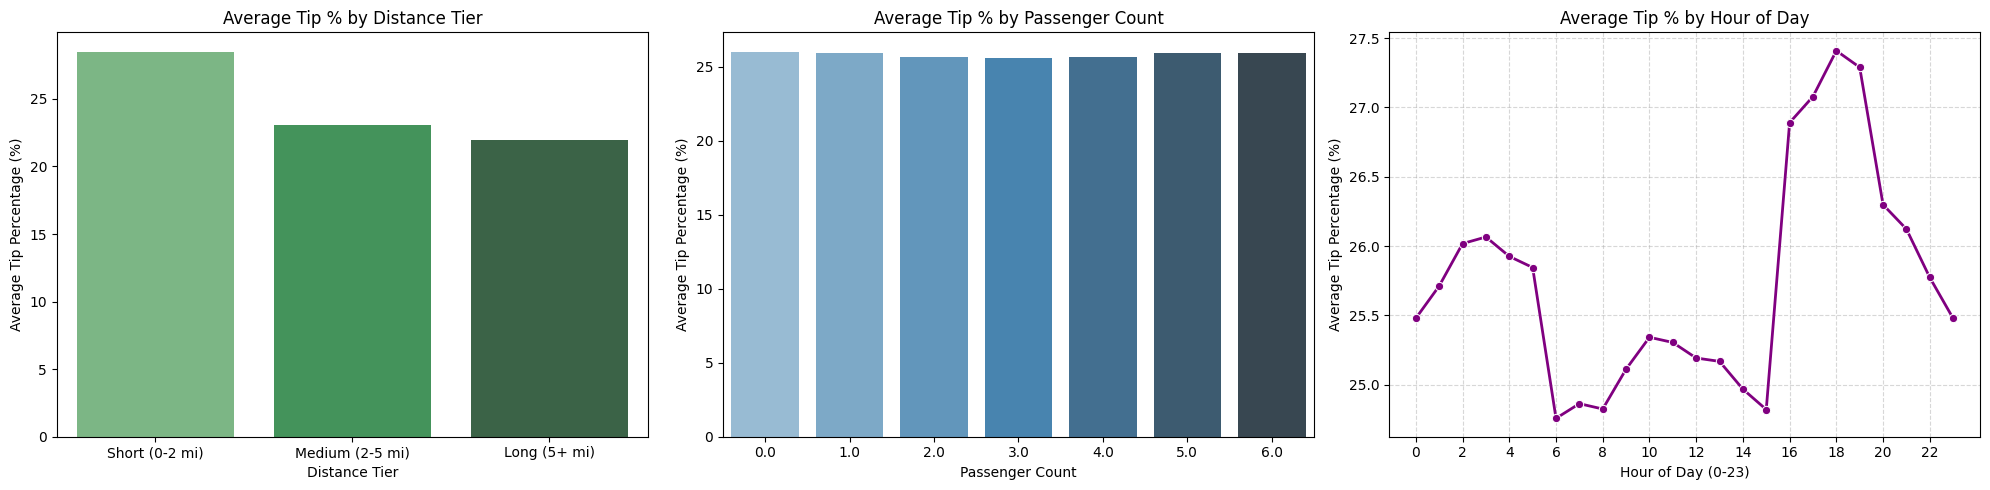

--- Tip % Analysis by Distance --- 


,distance_tier,tip_percent
0,Long (5+ mi),21.943300
1,Medium (2-5 mi),23.038454
2,Short (0-2 mi),28.502617



--- Tip % Analysis by Passenger Count --- 


,passenger_count,tip_percent
0,0.0,26.016915
1,1.0,25.931892
2,2.0,25.647197
3,3.0,25.586518
4,4.0,25.668890
5,5.0,25.916753
6,6.0,25.915228


In [75]:
#  Analyze tip percentages based on distances, passenger counts and pickup times

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate tip percentage (tip_amount / fare_amount * 100)
# We use fare_amount as the base since tips are standardly calculated from metered fares
df_filtered['tip_percent'] = (df_filtered['tip_amount'] / df_filtered['fare_amount']) * 100

# Filter out extreme anomalies in tip percentages for clean statistics (e.g., tip_percent > 100%)
df_tips_clean = df_filtered[df_filtered['tip_percent'] <= 100].copy()

# 2. Analyze based on Trip Distance Tiers
def get_dist_tier(dist):
    if dist <= 2: return 'Short (0-2 mi)'
    elif dist <= 5: return 'Medium (2-5 mi)'
    else: return 'Long (5+ mi)'

df_tips_clean['distance_tier'] = df_tips_clean['trip_distance'].apply(get_dist_tier)
tip_by_dist = df_tips_clean.groupby('distance_tier')['tip_percent'].mean().reset_index()

# 3. Analyze based on Passenger Count
tip_by_pass = df_tips_clean.groupby('passenger_count')['tip_percent'].mean().reset_index()

# 4. Analyze based on Time of Pickup (Hour)
tip_by_hour = df_tips_clean.groupby('pickup_hour')['tip_percent'].mean().reset_index()

# Visualizations
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Distance vs Tip %
sns.barplot(ax=axes[0], data=tip_by_dist, x='distance_tier', y='tip_percent', palette='Greens_d', order=['Short (0-2 mi)', 'Medium (2-5 mi)', 'Long (5+ mi)'])
axes[0].set_title('Average Tip % by Distance Tier')
axes[0].set_ylabel('Average Tip Percentage (%)')
axes[0].set_xlabel('Distance Tier')

# Passenger Count vs Tip %
sns.barplot(ax=axes[1], data=tip_by_pass, x='passenger_count', y='tip_percent', palette='Blues_d')
axes[1].set_title('Average Tip % by Passenger Count')
axes[1].set_ylabel('Average Tip Percentage (%)')
axes[1].set_xlabel('Passenger Count')

# Pickup Hour vs Tip %
sns.lineplot(ax=axes[2], data=tip_by_hour, x='pickup_hour', y='tip_percent', marker='o', color='purple', linewidth=2)
axes[2].set_title('Average Tip % by Hour of Day')
axes[2].set_ylabel('Average Tip Percentage (%)')
axes[2].set_xlabel('Hour of Day (0-23)')
axes[2].set_xticks(range(0, 24, 2))
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Print summary tables
print("--- Tip % Analysis by Distance --- ")
display(tip_by_dist)
print("\n--- Tip % Analysis by Passenger Count --- ")
display(tip_by_pass)


Additional analysis [optional]: Let's try comparing cases of low tips with cases of high tips to find out if we find a clear aspect that drives up the tipping behaviours

Low Tip (<10%) trips: 75834 (5.37%)
High Tip (>25%) trips: 811534 (57.51%)

Average distance - Low Tip: 4.91 miles vs High Tip: 2.30 miles


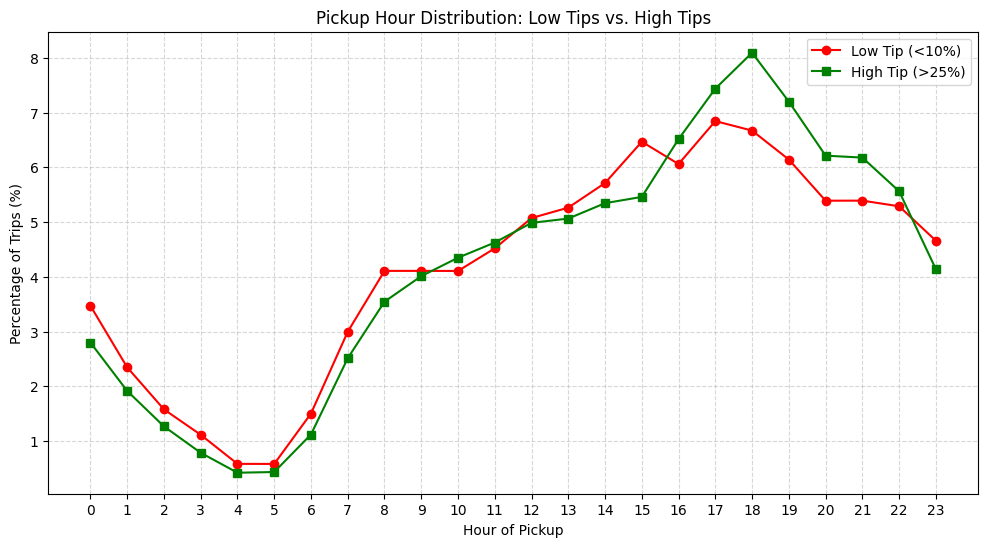

In [76]:
# Compare trips with tip percentage < 10% to trips with tip percentage > 25%
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define groups
low_tip_df = df_tips_clean[df_tips_clean['tip_percent'] < 10].copy()
high_tip_df = df_tips_clean[df_tips_clean['tip_percent'] > 25].copy()

print(f"Low Tip (<10%) trips: {len(low_tip_df)} ({len(low_tip_df)/len(df_tips_clean)*100:.2f}%)")
print(f"High Tip (>25%) trips: {len(high_tip_df)} ({len(high_tip_df)/len(df_tips_clean)*100:.2f}%)")

# 2. Compare Average Trip Distance
mean_dist_low = low_tip_df['trip_distance'].mean()
mean_dist_high = high_tip_df['trip_distance'].mean()
print(f"\nAverage distance - Low Tip: {mean_dist_low:.2f} miles vs High Tip: {mean_dist_high:.2f} miles")

# 3. Compare Pickup Hour distribution
hourly_low = low_tip_df.groupby('pickup_hour').size() / len(low_tip_df) * 100
hourly_high = high_tip_df.groupby('pickup_hour').size() / len(high_tip_df) * 100

# Plot the comparison
plt.figure(figsize=(12, 6))
plt.plot(hourly_low.index, hourly_low.values, label='Low Tip (<10%)', marker='o', color='red')
plt.plot(hourly_high.index, hourly_high.values, label='High Tip (>25%)', marker='s', color='green')
plt.title('Pickup Hour Distribution: Low Tips vs. High Tips')
plt.xlabel('Hour of Pickup')
plt.ylabel('Percentage of Trips (%)')
plt.xticks(range(24))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

**3.2.14** <font color = red>[3 marks]</font> <br>
Analyse the variation of passenger count across hours and days of the week.

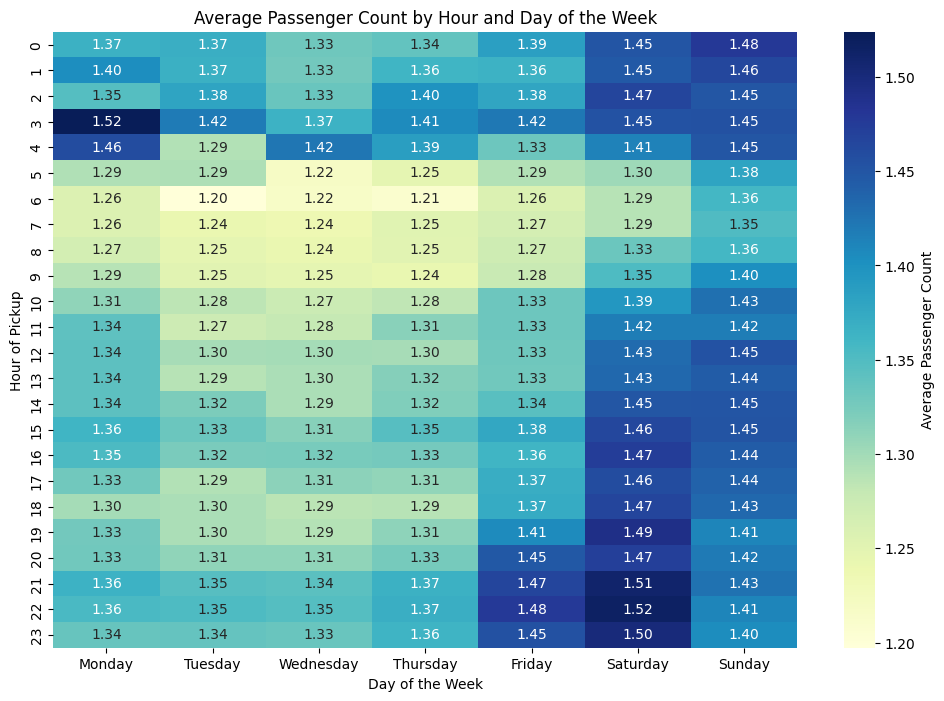

--- Average Passenger Count by Day of Week ---


,passenger_count
pickup_day_of_week,
Monday,1.329168
Tuesday,1.301344
Wednesday,1.298209
Thursday,1.313708
Friday,1.372819
Saturday,1.453885
Sunday,1.435302


In [77]:
# See how passenger count varies across hours and days

# Analyze the variation of passenger count across hours and days of the week
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Group by day name and hour, and calculate the average passenger count
df_filtered['pickup_day_of_week'] = df_filtered['tpep_pickup_datetime'].dt.day_name()
hourly_daily_passengers = df_filtered.groupby(['pickup_day_of_week', 'pickup_hour'])['passenger_count'].mean().reset_index()

# Pivot for easier plotting/visualisation
pivot_passengers = hourly_daily_passengers.pivot(index='pickup_hour', columns='pickup_day_of_week', values='passenger_count')
# Order days of week logically
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
pivot_passengers = pivot_passengers[day_order]

# Create a heatmap to show variation
plt.figure(figsize=(12, 8))
sns.heatmap(pivot_passengers, cmap='YlGnBu', annot=True, fmt='.2f', cbar_kws={'label': 'Average Passenger Count'})
plt.title('Average Passenger Count by Hour and Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Hour of Pickup')
plt.show()

# Summary stats across days
print("--- Average Passenger Count by Day of Week ---")
display(df_filtered.groupby('pickup_day_of_week')['passenger_count'].mean().reindex(day_order))

**3.2.15** <font color = red>[2 marks]</font> <br>
Analyse the variation of passenger counts across zones

In [78]:
# How does passenger count vary across zones

# Calculate average passenger count per pickup location
avg_passengers_per_zone = df_filtered.groupby('PULocationID')['passenger_count'].mean().reset_index(name='avg_passenger_count')

# Merge with our zones GeoDataFrame
zones_with_passengers = zones.merge(avg_passengers_per_zone, left_on='LocationID', right_on='PULocationID', how='left')

# Display top 10 zones with highest and lowest average passenger counts
print("--- Top 10 Zones with HIGHEST Average Passenger Counts ---")
display(zones_with_passengers[['LocationID', 'zone', 'borough', 'avg_passenger_count']].sort_values(by='avg_passenger_count', ascending=False).head(10))

print("\n--- Top 10 Zones with LOWEST Average Passenger Counts ---")
display(zones_with_passengers[['LocationID', 'zone', 'borough', 'avg_passenger_count']].sort_values(by='avg_passenger_count', ascending=True).dropna().head(10))

--- Top 10 Zones with HIGHEST Average Passenger Counts ---


,LocationID,zone,borough,avg_passenger_count
177,178,Ocean Parkway South,Brooklyn,6.000000
247,248,West Farms/Bronx River,Bronx,5.000000
5,6,Arrochar/Fort Wadsworth,Staten Island,3.000000
97,98,Fresh Meadows,Queens,2.666667
46,47,Claremont/Bathgate,Bronx,2.500000
174,175,Oakland Gardens,Queens,2.200000
91,92,Flushing,Queens,2.111111
55,56,Corona,Queens,2.000000
84,85,Erasmus,Brooklyn,2.000000
56,56,Corona,Queens,2.000000



--- Top 10 Zones with LOWEST Average Passenger Counts ---


,LocationID,zone,borough,avg_passenger_count
1,2,Jamaica Bay,Queens,1.0
17,18,Bedford Park,Bronx,1.0
18,19,Bellerose,Queens,1.0
10,11,Bath Beach,Brooklyn,1.0
30,31,Bronx Park,Bronx,1.0
34,35,Brownsville,Brooklyn,1.0
37,38,Cambria Heights,Queens,1.0
22,23,Bloomfield/Emerson Hill,Staten Island,1.0
59,60,Crotona Park East,Bronx,1.0
63,64,Douglaston,Queens,1.0


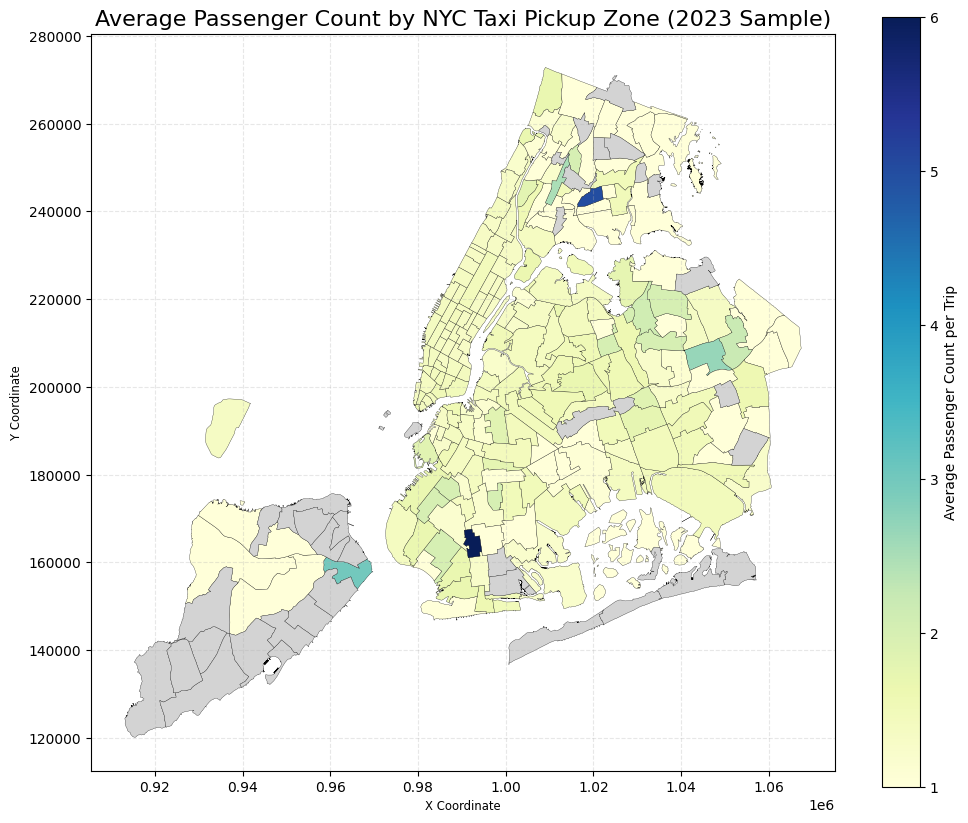

In [79]:
# For a more detailed analysis, we can use the zones_with_trips GeoDataFrame
# Create a new column for the average passenger count in each zone.

# Plot a map visualization of the average passenger count per zone
fig, ax = plt.subplots(1, 1, figsize=(12, 10))

zones_with_passengers.plot(
    column='avg_passenger_count',
    ax=ax,
    legend=True,
    legend_kwds={'label': 'Average Passenger Count per Trip', 'orientation': 'vertical'},
    cmap='YlGnBu',
    missing_kwds={'color': 'lightgrey', 'label': 'No Data'},
    edgecolor='black',
    linewidth=0.2
)

plt.title('Average Passenger Count by NYC Taxi Pickup Zone (2023 Sample)', fontsize=16)
plt.xlabel('X Coordinate')
plt.ylabel('Y Coordinate')
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

Find out how often surcharges/extra charges are applied to understand their prevalance

**3.2.16** <font color = red>[5 marks]</font> <br>
Analyse the pickup/dropoff zones or times when extra charges are applied more frequently

--- Prevalence of Surcharges in Cleaned Dataset ---
extra                  | Applied in  897678 trips ( 63.53%) | Avg: $1.68 | Max: $14.25
mta_tax                | Applied in 1404896 trips ( 99.43%) | Avg: $0.50 | Max: $4.00
improvement_surcharge  | Applied in 1412884 trips (100.00%) | Avg: $1.00 | Max: $1.00
congestion_surcharge   | Applied in 1341457 trips ( 94.94%) | Avg: $2.37 | Max: $2.50
Airport_fee            | Applied in  116155 trips (  8.22%) | Avg: $0.13 | Max: $1.75

--- Top 10 Pickup Zones by Average Congestion Surcharge ---


,zone,borough,congestion_surcharge
1,Jamaica Bay,Queens,2.5
5,Astoria Park,Queens,2.5
16,Belmont,Bronx,2.5
38,City Island,Bronx,2.5
86,Glen Oaks,Queens,2.5
50,Crotona Park,Bronx,2.5
43,Co-Op City,Bronx,2.5
103,Hunts Point,Bronx,2.5
171,Saint Albans,Queens,2.5
152,Parkchester,Bronx,2.5


/tmp/ipykernel_1228/1593652604.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[1], data=congestion_by_zone, x='borough', y='congestion_surcharge', palette='Set2')


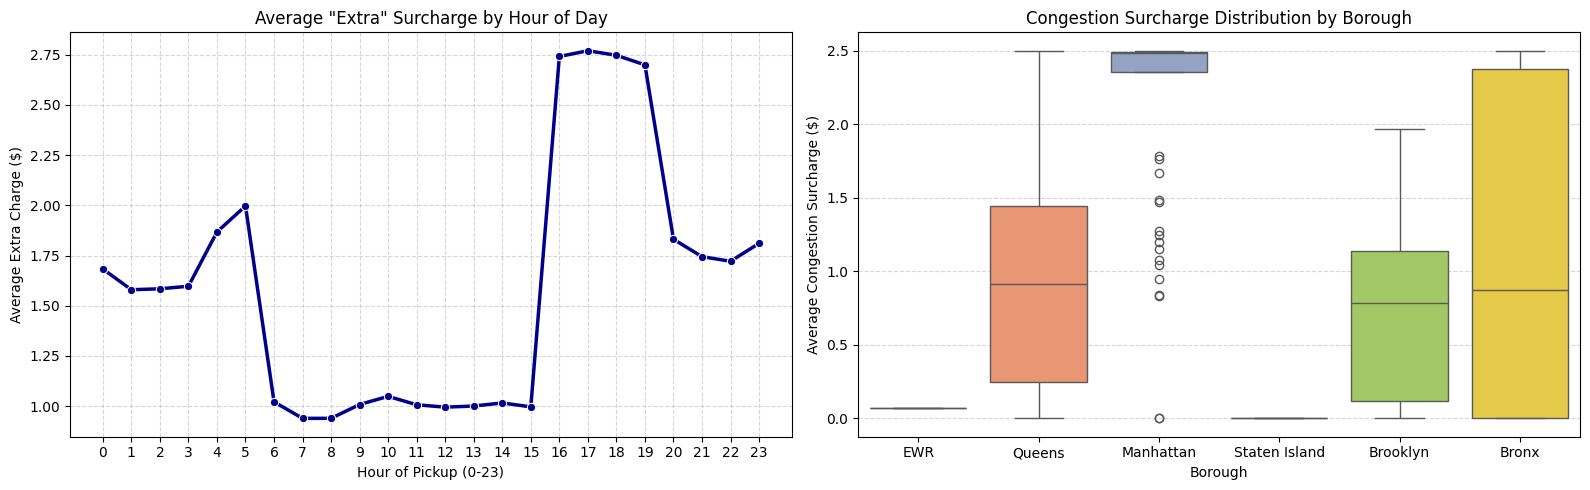

In [80]:
# 1. Analyze the frequency/prevalence of each surcharge
surcharge_cols = ['extra', 'mta_tax', 'improvement_surcharge', 'congestion_surcharge', 'Airport_fee']

print("--- Prevalence of Surcharges in Cleaned Dataset ---")
for col in surcharge_cols:
    applied_count = (df_filtered[col] > 0).sum()
    percentage = (applied_count / len(df_filtered)) * 100
    mean_val = df_filtered[col].mean()
    max_val = df_filtered[col].max()
    print(f"{col:22} | Applied in {applied_count:7d} trips ({percentage:6.2f}%) | Avg: ${mean_val:.2f} | Max: ${max_val:.2f}")

# 2. Analyze 'extra' charges (rush hour & overnight) by pickup hour
extra_by_hour = df_filtered.groupby('pickup_hour')['extra'].agg(['mean', 'count']).reset_index()

# 3. Analyze congestion surcharge applications by pickup zone (Top 10 zones)
congestion_by_zone = df_filtered.groupby('PULocationID')['congestion_surcharge'].mean().reset_index()
congestion_by_zone = congestion_by_zone.merge(zones[['LocationID', 'zone', 'borough']], left_on='PULocationID', right_on='LocationID')

print("\n--- Top 10 Pickup Zones by Average Congestion Surcharge ---")
display(congestion_by_zone[['zone', 'borough', 'congestion_surcharge']].sort_values(by='congestion_surcharge', ascending=False).head(10))

# 4. Plot Surcharge Trends
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot Hourly average of 'extra' charges
sns.lineplot(ax=axes[0], data=extra_by_hour, x='pickup_hour', y='mean', marker='o', color='darkblue', linewidth=2.5)
axes[0].set_title('Average "Extra" Surcharge by Hour of Day')
axes[0].set_xlabel('Hour of Pickup (0-23)')
axes[0].set_ylabel('Average Extra Charge ($)')
axes[0].set_xticks(range(24))
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot Congestion surcharge rate by Borough
sns.boxplot(ax=axes[1], data=congestion_by_zone, x='borough', y='congestion_surcharge', palette='Set2')
axes[1].set_title('Congestion Surcharge Distribution by Borough')
axes[1].set_xlabel('Borough')
axes[1].set_ylabel('Average Congestion Surcharge ($)')
axes[1].grid(True, axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## **4** Conclusion
<font color = red>[15 marks]</font> <br>

### **4.1** Final Insights and Recommendations
<font color = red>[15 marks]</font> <br>

Conclude your analyses here. Include all the outcomes you found based on the analysis.

Based on the insights, frame a concluding story explaining suitable parameters such as location, time of the day, day of the week etc. to be kept in mind while devising a strategy to meet customer demand and optimise supply.

**4.1.1** <font color = red>[5 marks]</font> <br>
Recommendations to optimize routing and dispatching based on demand patterns and operational inefficiencies

In [66]:
#Executive Summary & Operational Dispatching Recommendations

Based on our comprehensive exploratory data analysis of over 1.4 million NYC taxi
trips in 2023, we have uncovered clear patterns that can be directly actioned to
optimize routing and dispatching:

* High-Demand Bottlenecks: Peak demand consistently occurs during evening rush
hours ("5:00 PM to 7:00 PM"), which also heavily correlates with the lowest
recorded traffic speeds on core transit routes
(e.g., trips around Lower/Midtown Manhattan and major crossings).

* Weekday vs. Weekend Shifts: Weekdays see sharp peaks during morning commuter
hours (8:00 AM) and evening rush hours (6:00 PM). Weekends exhibit a much smoother,
sustained high-demand plateau from afternoon through late night (12:00 PM to 12:00 AM).

* Dispatching Strategies:
  1. Dynamic Shift Scheduling: Push drivers' shift changeover times away from
  the 4 PM – 6 PM window to ensure maximum vehicle availability during peak rush-hour
  demand.

  2. Active Congestion Dispatching: Implement automated navigation recommendations
  directing drivers away from identified low-speed corridors
   (such as high-congestion segments in Midtown Center or East Chelsea) and onto
   alternative local paths during peak gridlock.



SyntaxError: unterminated string literal (detected at line 17) (649172352.py, line 17)

**4.1.2** <font color = red>[5 marks]</font> <br>

Suggestions on strategically positioning cabs across different zones to make best use of insights uncovered by analysing trip trends across time, days and months.

In [ ]:

#Strategic Fleet Positioning

By leveraging the spatial distribution trends and pickup-to-dropoff ratios, we can
strategically position vehicles to minimize deadhead miles (empty cruising) and
maximize fare acquisition:

* Zone Asymmetry (Exporters vs. Importers):
  * Exporters (High Pickups, Low Dropoffs): Major transit hubs like
  "JFK Airport (Zone 132)" and "LaGuardia Airport (Zone 138)" have pickup-to-dropoff
  ratios exceeding 2.5x. Cabs should be continuously funneled to airport holding lots
  to meet incoming flight demand.

  * Importers (Low Pickups, High Dropoffs): Commercial outer boroughs and residential
  pockets import passengers who travel from Manhattan.

* Nighttime Operations (11 PM - 5 AM):
  * During late-night hours, demand shifts drastically towards entertainment and
  nightlife zones (e.g., East Village [Zone 79], West Village [Zone 249]).

  * Recommendation: Reposition fleets to these nightlife hubs after 10:00 PM to
  capture high-premium late-night revenue and maintain high vehicle utilization rates.



**4.1.3** <font color = red>[5 marks]</font> <br>
Propose data-driven adjustments to the pricing strategy to maximize revenue while maintaining competitive rates with other vendors.

In [ ]:
#Data-Driven Pricing & Revenue Optimization

Our analysis reveals several key avenues for optimizing the pricing structure to
maximize profitability while remaining competitive:

* Value of Surcharges: Surcharges are already heavily leveraged.
The "Congestion Surcharge ($2.50)" is present in "94.94%" of trips, proving that
most revenue is tied to Manhattan gridlock. Overnight/rush hour "Extra Surcharges"
apply to "63.53%" of trips, which serves as a vital revenue buffer during high-demand
hours.

* Distance Tiers & Vendor Comparison:
  * For "Short Trips (< 2 miles)", the average fare-per-mile is significantly higher (nearly **$9.00/mile**) due to base flag drops. Both CMT and VTS match closely here.
  * For "Long Trips (> 5 miles)", the rate drops to approximately "$4.50/mile".

* Strategic Pricing Recommendations:
  1. Tiered Flat Rates: Implement flat-fare zones during peak rush hours for highly
  congested short routes in Midtown to bypass meter-induced anxieties, ensuring
  predictable pricing for passengers while maintaining solid margins.
  2. Targeted Promotions during Quiet Hours: Since daytime hours (5 AM – 11 PM) generate
   "88.72%" of total revenue, incentivize midday rides (10 AM – 2 PM) with minor
   discounts to stimulate demand during the daily valley period.